# Save the Human (in the loop): when does human oversight of AI actually reduce risk? — Results

This notebook shows the results of the study set out in the project outline. It computes them itself, section by section, from the public FiFAR dataset. Starting from the dataset's alerts file and the framework's Classifier h, it regenerates the simulated reviewers, draws the teams, runs the three policies, re-draws the cases to give every difference a range, and applies the rules that decide the hypothesis. The outputs below are those of the run on free Google Colab that produced this copy. The notebook puts the deciding results first, then the descriptive ones; the problem and the objective are set out in the report. Where the study departs from the project outline, the departure is explained where it first matters. Technical records (run time and memory of this run, input checksums, and how each item traces to the study's design) are at the end and are not needed to read the results.

**Data.** Financial Fraud Alert Review Dataset (FiFAR), version 1 (Alves et al., 2025), figshare, digital object identifier 10.6084/m9.figshare.28351172 (https://doi.org/10.6084/m9.figshare.28351172), licensed under CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/). The dataset is described in Alves et al., "A benchmarking framework and dataset for learning to defer in human-AI decision-making", *Scientific Data* 12, 506 (2025), https://doi.org/10.1038/s41597-025-04664-y. The notebook downloads the dataset and uses it unmodified; the repository does not redistribute it. The dataset's `Base.csv` derives from the Bank Account Fraud dataset, which is credited in the README, section "Data: FiFAR" ([https://github.com/zsipka/SaveHITL-pub#data-fifar](https://github.com/zsipka/SaveHITL-pub#data-fifar)); this notebook downloads that file and checks its checksum. The results are computed from FiFAR by this project and are not part of it. Of `Base.csv` itself, the notebook shows only aggregate figures (rates, counts and correlations over groups of at least 10 applications); no application row or individual value is shown.

The tables and graphs this notebook produces are computed from FiFAR (Alves et al., figshare, 2025, https://doi.org/10.6084/m9.figshare.28351172, CC BY 4.0, https://creativecommons.org/licenses/by/4.0/). They are derived from FiFAR by this project, not part of it, and FiFAR's creators have not reviewed or endorsed them.

**Files in `results/`: derived from FiFAR.** This project made the three files in `results/` from its runs on FiFAR (https://doi.org/10.6084/m9.figshare.28351172, CC BY 4.0, https://creativecommons.org/licenses/by/4.0/). They are derived from FiFAR, not part of it.

- `router_selected_settings.csv`: the settings chosen for each of the 250 router models, with the weighted log-loss of the selected trial (column `selected_weighted_log_loss`), which this project computed on FiFAR.
- `router_model_checksums.csv`: the checksums of the 250 router models this project trained on FiFAR.
- `input_checksums.csv`: the paths, sizes and checksums of the input files, 132 from FiFAR and 10 from OpenL2D (Apache License 2.0, see `NOTICE`).

They hold no FiFAR case row and no data value from FiFAR: no feature, label, score, reviewer decision or reviewer parameter. To show what each row refers to, they reuse FiFAR's own reviewer labels (for example `standard#13`) and FiFAR's file paths and file sizes. FiFAR's creators have not reviewed or endorsed these files.

## Contents

- [1. Running the notebook](#1-running-the-notebook)
- [2. The data and the set-up](#2-the-data-and-the-set-up)
- [3. Hypothesis](#3-hypothesis)
- [4. Descriptive results](#4-descriptive-results)
- [5. Limitations and risks](#5-limitations-and-risks)
- [Appendix](#appendix)
- [The switch in this run](#the-switch-in-this-run)
- [Input checksums](#input-checksums)
- [Map from each item to its design identifier](#map-from-each-item-to-its-design-identifier)
- [Label texts](#label-texts)
- [The results that decide, in full](#the-results-that-decide-in-full)
- [Boundary summaries: caveat](#boundary-summaries-caveat)
- [Run time and memory of this run](#run-time-and-memory-of-this-run)
- [This run's outputs in one archive](#this-runs-outputs-in-one-archive)

<a id="1-running-the-notebook"></a>
## 1. Running the notebook

**What the run does.** Open the notebook in Google Colab from [the repository](https://github.com/zsipka/SaveHITL-pub), or run it on your own machine with the repository's environment file; Colab is the tested route. Run the cells in order. The run:
1. sets up the environment;
2. clones the framework and applies the project's four patches;
3. downloads the FiFAR data from figshare;
4. computes every section in turn.

We chose not to retrain all models from the framework for efficiency reasons. The models used and trained are introduced in [The data and the set-up](#2-the-data-and-the-set-up). We have pre-run the hyper parameter search for the trained models. The Notebook is loading the settings from this search by default but leaves the option to re-run the search (see the switch below).

**Permission to download.** The next cell asks for your permission to download FiFAR from figshare. Nothing is downloaded until you give it.

In [1]:
# Settings
FIFAR_DOWNLOAD_ALLOWED = True   # set to True to give permission to download FiFAR from figshare (CC BY 4.0);
                                 # nothing is downloaded, and the run stops at the set-up, until it is True

**The switch**:

In [2]:
# HYPERPARAM_TUNE
# False (default): the router's 250 models are refitted by the framework's own
#   procedure from the settings the study's settings search chose
#   (results/router_selected_settings.csv). This reproduces the study's figures.
# True: the framework's full settings search runs first, 120 trials per model,
#   then the run continues as normal. About 7 hours on a typical laptop;
#   14 to 21 hours on free Colab, which is more than one free session.
HYPERPARAM_TUNE = False

In [3]:
# The repository: this notebook's own folder when it is run from a clone of SaveHITL-pub; otherwise (Colab) a fresh
# clone. Then the run's layout and the state of the switch.
import os, sys, subprocess
REPOSITORY = "https://github.com/zsipka/SaveHITL-pub.git"
if not os.path.isdir("savehitl"):
    if not os.path.isdir("SaveHITL-pub"):
        subprocess.run(["git", "clone", "-q", REPOSITORY, "SaveHITL-pub"], check=True)
    os.chdir("SaveHITL-pub")
sys.path.insert(0, os.getcwd())
from savehitl import notebook as nb
nb.start(HYPERPARAM_TUNE);

HYPERPARAM_TUNE = False


> ⚠️ Runtime estimate (Colab free): **4 minutes**

In [4]:
# Environment (Python 3.7.9 and the pinned versions), the framework at its pinned commit with the four patches, and
# FiFAR from figshare; every file is stopped on its sha256. Each part runs once per session.
nb.setup(FIFAR_DOWNLOAD_ALLOWED)

environment versions
Environment ready (133 s).
Framework ready at cfe5fd0 with the patches (12 s).
FiFAR ready: 132 files, each equal to its checksum (16 s).


<a id="2-the-data-and-the-set-up"></a>
## 2. The data and the set-up

**The data.** The study uses FiFAR, which is built on the Bank Account Fraud dataset: 1,000,000 generated bank account applications over eight months, each labelled as fraud or legitimate (file `Base.csv`). The dataset's Alert Model scores every application from month 3 on and flags those above a cut-off, set so that 5% of the legitimate applications of month 3 are flagged. The 30,622 flagged applications are the alerts, and only alerts reach Classifier h or a reviewer. The results are measured on month 7, the test month, whose 4,457 alerts (711 frauds, 3,746 legitimate) are the cases the policies decide.

Frauds that the alert model does not flag are ignored in this study. Frauds can be controlled by the alert threshold in practice. We use fixed threshold at 5% false positive rate.

**Which months are used for what.** Months are numbered 0 to 7, as in the data files. The graph shows which months each model and the reviewers learn from or are set on, and which month gives the results. Month 7, the test month, is used only for results: nothing is learned, chosen or set on it.

The next cell computes the aggregate figures of `Base.csv` (1,000,000 applications), which both graphs of this section read.
> ⚠️ Runtime estimate (Colab free): 1 minute

the applications: aggregate figures of Base.csv: done in 34 s.


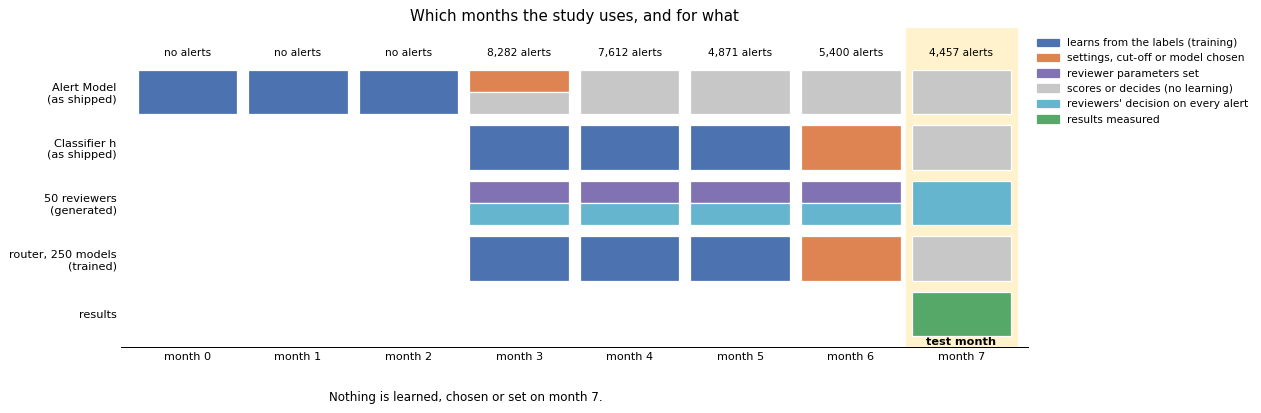

In [5]:
nb.section("F-months")

These figures summarise FiFAR's `Base.csv` in aggregate: rates, counts and correlations over groups of at least 10 applications. They show no individual application or value.

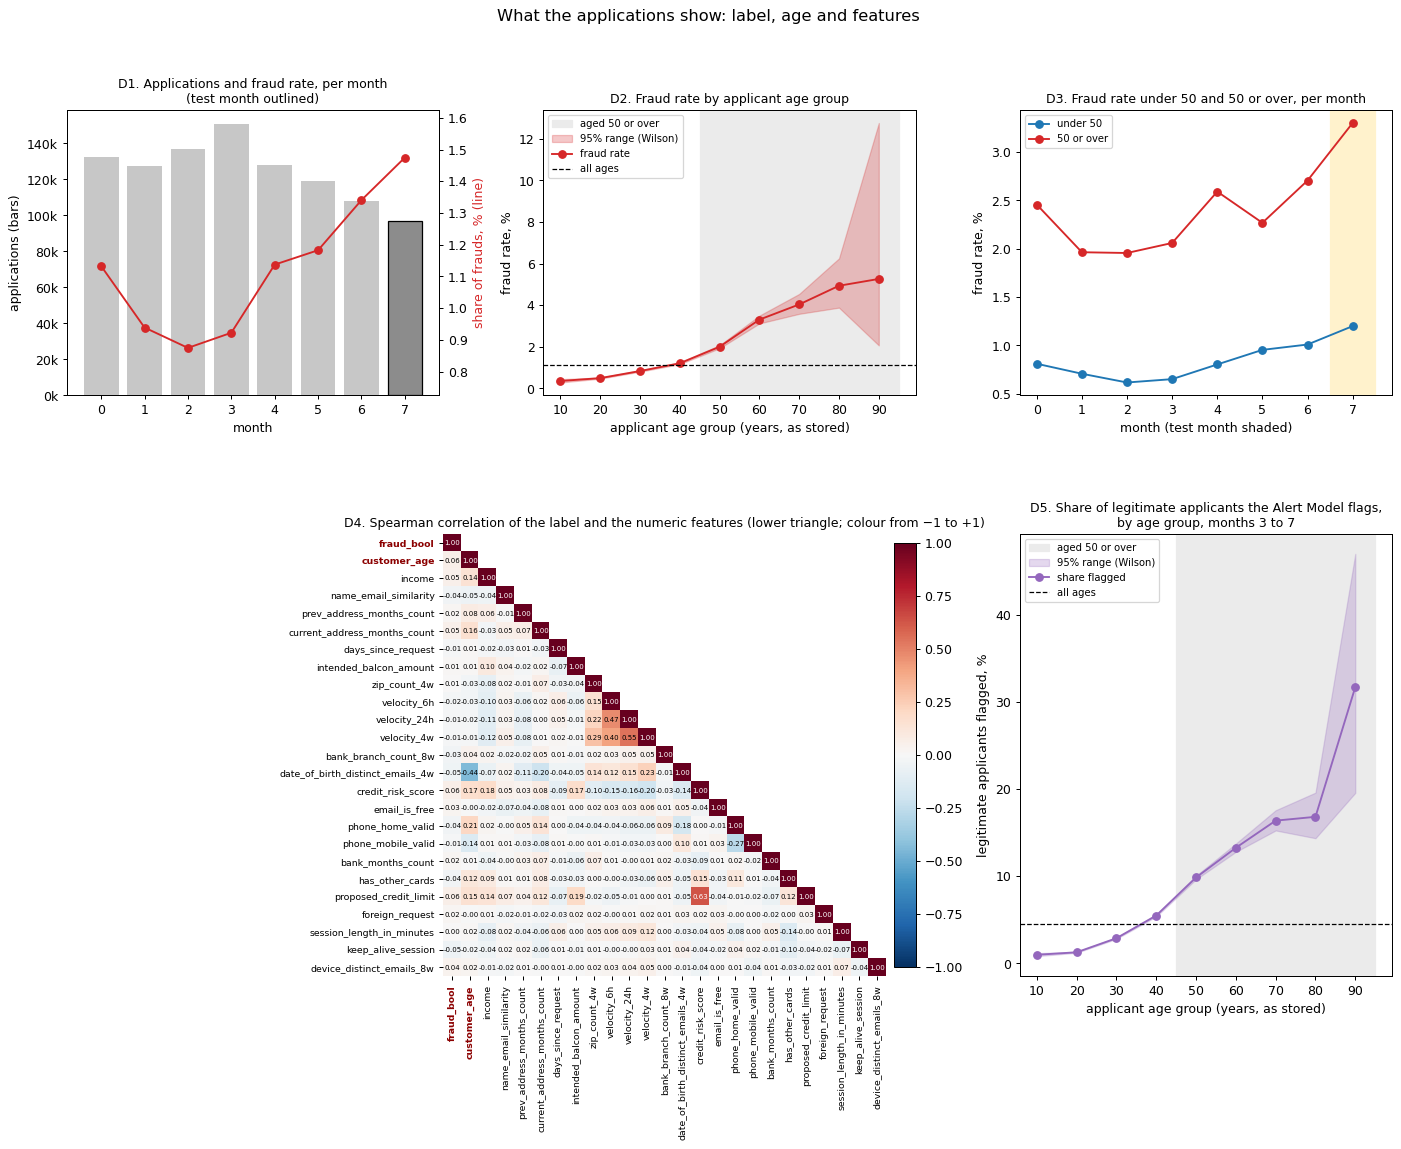

In [6]:
nb.section("F-data")

D4 leaves out:
- **categorical features**, whose values have no order to rank: `payment_type`, `employment_status`, `housing_status`, `source`, `device_os`;
- **`device_fraud_count`**, which has the same value for every application;
- **`month`**, the time index used to split the data, not a property of the applicant.

(1) The applications as the dataset provides them, before any model. Descriptive.

(2) In every month, fraud is more frequent among applicants aged 50 or over than among younger applicants, and in point value its rate rises from one age group to the next. Age therefore carries information about the label, so a model that takes age as an input can learn to flag older applicants more often; the Alert Model and Classifier h both take it as an input. The Alert Model does flag a larger share of older legitimate applicants, and this part is the same under every policy. Among the features, `date_of_birth_distinct_emails_4w`, `phone_home_valid`, `credit_risk_score` and `current_address_months_count` are the most correlated with age, so they too carry information about age. None of this shows that age causes fraud, that the models are unfair by design, or that this is the only source of the age gaps in the results.

(3) It decides nothing.

**Reviewers.** The notebook generates the 50 reviewers with the dataset's own generator. This is not model fitting in the machine-learning sense: a reviewer does not learn from data. Each reviewer takes the true label of an alert and gets it wrong with a probability given by a fixed formula of the alert's features. The generator draws the formula's weights at random, then sets two offsets so that, on the alerts of months 3 to 6, the reviewer's FPR (legitimate applications wrongly rejected ÷ all legitimate) and FNR (frauds wrongly accepted ÷ all frauds) match targets drawn for it.

**Teams.** A team has ten reviewers and is run in five versions: five disjoint sets of ten, drawn at random from the 50 with a fixed seed. Within a version, the three teams are made of the same ten reviewers and differ only in how they decide a reviewed alert:
- **Team A, standard mixed team (the control):** members' own decision stands.
- **Team B, agrees with the model:** members follow the model in 4 of 5 reviewed cases, picked at random; otherwise their own decision stands.
- **Team C, biased:** members reject older applicants (aged 50 or over) whenever the model would.

The precise behaviour of each team is fixed by the teams' decision rules in the design. Capacity is not a property of a team: every team is run at every capacity.

**Models.** Two models are re-used from the dataset for efficiency reasons. Others are rebuilt.

_Re-used models_:
1. _Alert Model_ - a LightGBM model that assigns each application a fraud score (i.e. creates alerts)
2. _Classifier h_ - a LightGBM model that classifies alerts

_Trained models:_

_Routers_ - the models that predict how likely each reviewer is to decide an alert correctly: one model per reviewer, for each team version and each of five training shuffles, **250 in all**. The routers' hyperparameter tuning was run in advance, and by default the notebook refits the models from the settings it chose (the switch at the top).

**What is varied.** Capacity: 0 to 1 in steps of 0.05, plus 10/11 (22 values). Every combination of team, version, random order, capacity and cost ratio is run and reported.

**How to read the results.**

- **Capacity**: the share of the test month's alerts a team can review, from 0 (none) to 1 (all). The realistic range is 0.65 to 1, which includes 10/11, the share the benchmark gives its own reviewers. At 0.75 the project outline counts capacity as materially exceeded; there teams B and C are also compared with team A.
- **Cost ratio** λ: the cost of wrongly rejecting a legitimate applicant divided by the cost of missing a fraud. The main results use 0.057, the ratio Classifier h was trained for. Results for other values of λ are also shown (descriptive): 0.035, 0.0537 and 0.171.
- **Three measures, never combined; lower is better**: misclassification cost, frauds accepted (regulatory exposure), and the size of the age gap (fairness exposure). The first and the last are defined below.
- **Differences**: the policy named first minus the one it is compared with, on the same alerts. Below zero favours the policy named first.
- **Verdicts**: each difference has a range, from re-drawing the test month's alerts. ✅ **beats**: the whole range is below zero. ❌ **does worse**: the whole range is above zero. 🟡 **no difference shown**: the range includes zero. A star (✅*, ❌*, 🟡*) marks a deciding result.
- **Deciding and descriptive**: the deciding results are named in the design. Their ranges are widened so that, across all of them, the chance of a false finding stays near 5%. All other results are descriptive: they have ordinary 95% ranges and decide nothing. Where the two differ, the deciding verdict governs.
- **Versions**: a team beats or does worse only if all five versions do; otherwise the average of the five decides. Each version is run with five random orders of the alerts, and the results are averaged over them.
- **"By construction"** marks a figure that follows from the rules themselves: a check, never a finding.
- **A dash (—)** in a table marks an empty cell: the figure or note does not apply to that row.

> **Important: every FPR in this notebook is taken among the alerts, not over all applications.** The reason: the study assesses how effective human review is, and the alerts are its starting point. Applications the Alert Model did not flag, including the frauds it missed, are outside the study. Because the alerts are applications already flagged as suspicious, the FPRs here are much higher than a bank's rejection rate across all applicants.

**Age gap** = FPR<sub>50+</sub> − FPR<sub>&lt;50</sub> = (wrongly rejected 50+ ÷ legitimate 50+) − (wrongly rejected &lt;50 ÷ legitimate &lt;50)

**Size of the age gap** = | age gap |

**Misclassification cost** = FN + λ × FP, summed over the alerts (λ = cost ratio; 0.057 unless another ratio is stated). The project outline calls it 'expected loss'.

<a id="3-hypothesis"></a>
## 3. Hypothesis

**What "deferral" means in this study.** The study replaces calibrated deferral with analyst-aware deferral (one of the aspirational extensions) as it better illustrates the objective.

The hypothesis has two parts. **First**, across realistic review capacity, analyst-aware deferral achieves lower risk than both full automation and naive review of every alert. **Second**, naive review can be worse than full automation when capacity is exceeded or when reviewers largely agree with the model.

**The three policies**, named by number in the tables:
- **policy 1, full automation**: Classifier h decides every alert;
- **policy 2, naive review**: every alert is meant for review; the team reviews as many as its capacity allows, and every alert beyond capacity is confirmed without review, so the application is rejected (i.e. zero regulatory exposure for alerts beyond capacity);
- **policy 3, analyst-aware deferral**: each alert is sent to either a reviewer or the model (Classifier h), decided based on their likeliness to decide correctly. Specifically, by comparing Classifier h confidence (the larger of its fraud and no-fraud probabilities) with router's score (how likely is that the analyst decides correctly), subject to team capacity and bias.

**The automated baseline.** Full automation reproduces the total cost the benchmark publishes for Classifier h on the test month (Alves et al., 2025, p. 24, Table 7).

**How the results are told.** The results are told policy by policy. Naive review (3.1) and analyst-aware deferral (3.2) are each compared with full automation, and analyst-aware deferral is also compared with naive review. The teams are the conditions each policy is tested under: team A, the control, at full capacity; team B, reviewers who agree with the model, and team C, reviewers biased against applicants aged 50 or over, both across the realistic range 0.65 to 1. The verdicts that decide are those of sections 3.1 and 3.2, judged in section 3.3. For each policy, team and measure, section 4.1 also gives the capacity range over which the policy beats full automation. Those ranges are descriptive: they decide nothing, and where one differs from a deciding verdict, the deciding verdict governs.

<a id="31-naive-review-against-full-automation"></a>
### 3.1 Naive review against full automation

The tables and graphs this notebook produces are computed from FiFAR (Alves et al., figshare, 2025, https://doi.org/10.6084/m9.figshare.28351172, CC BY 4.0, https://creativecommons.org/licenses/by/4.0/). They are derived from FiFAR by this project, not part of it, and FiFAR's creators have not reviewed or endorsed them.

The next cell regenerates the 50 reviewers, draws the teams, runs full automation and naive review, and re-draws the cases 50,000 times.
> ⚠️ Runtime estimate (Colab free): **5 minutes**

regenerating the 50 reviewers: done in 72 s.
drawing the five teams: done in 1 s.
policy 1, full automation: done in 1 s.
policy 1, ranges (1,000 re-draws): done in 1 s.
policy 2, naive review (replay): done in 4 s.
policy 2, re-drawing the cases (50,000): done in 149 s.
policy 2, verdicts: done in 16 s.


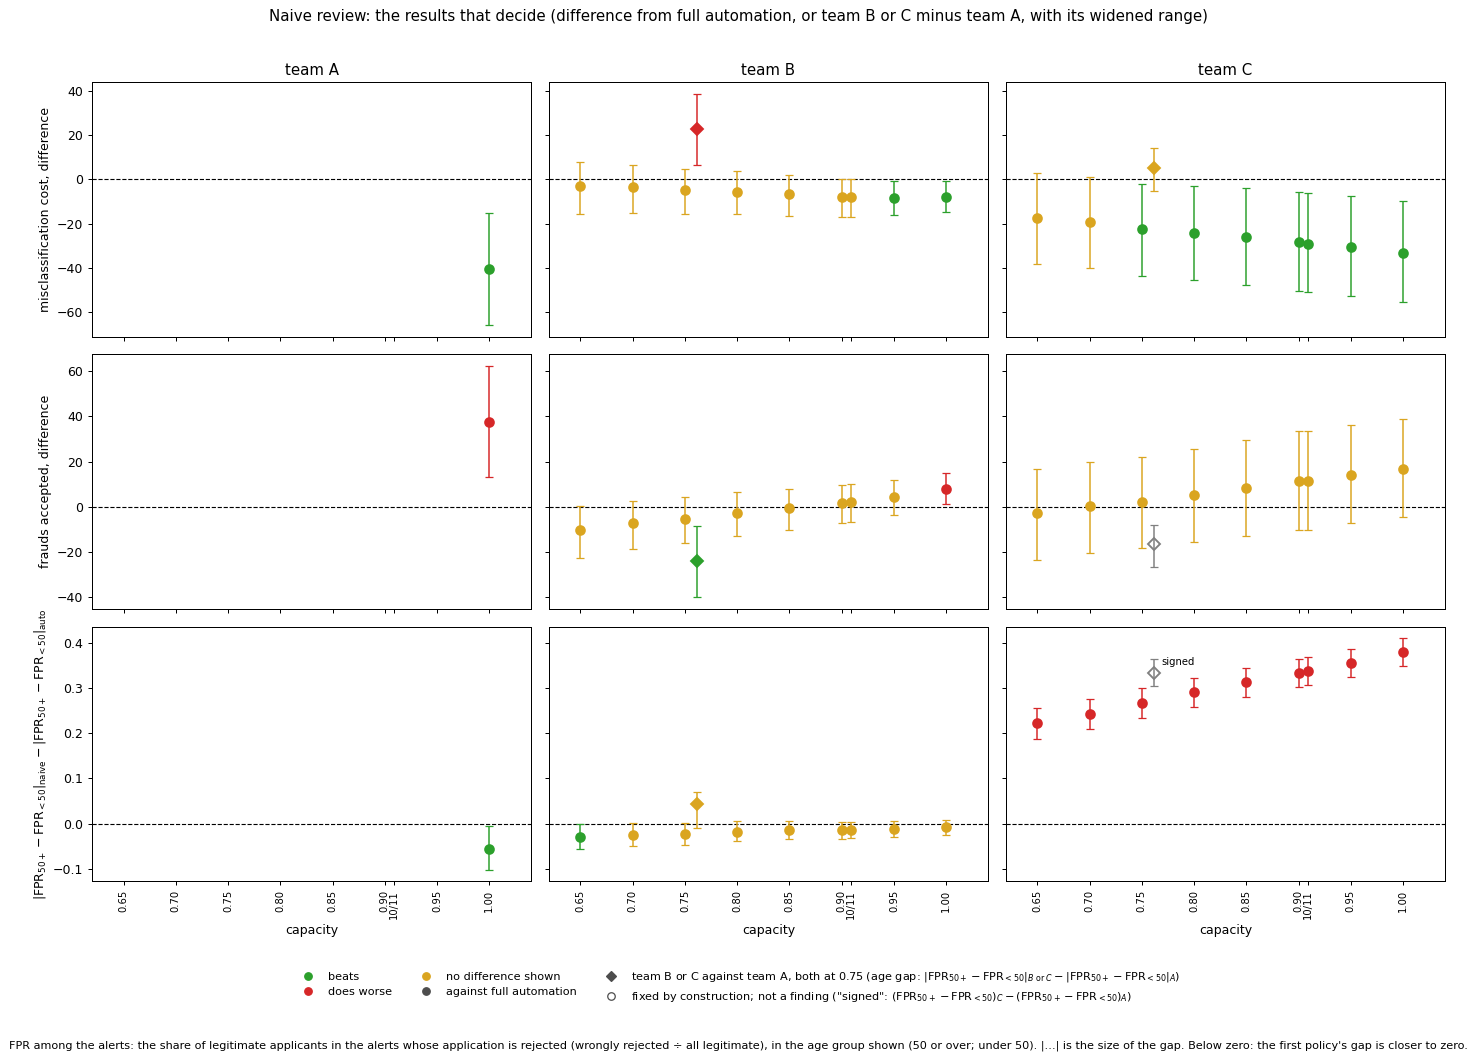

In [7]:
nb.section("P2-F10")

(1) The grid shows every deciding result of naive review: one row per measure (for the age gap, its size), one column per team, capacity across, and the difference from full automation with its range; the colour gives the verdict. In the panels of teams B and C, a second marker shows the team against team A, both at capacity 0.75. These are the results that decide the second part of the hypothesis, and with section 3.2, the refutation conditions. They are judged only at the capacities the project outline judges: team A at full capacity, and teams B and C across the realistic range, 0.65 to 1; lower capacities are shown but not judged. The full sweep over every capacity is descriptive and decides nothing: see [section 4](#4-descriptive-results) and `tables/P2-T5_full_sweep.csv`.

(2) On misclassification cost, naive review beats full automation with team A at full capacity, with team B only at the highest realistic capacities, and with team C except at the lowest realistic capacities. On frauds accepted, it does worse with team A at full capacity and with team B only at full capacity, and shows no difference with team C. On the age gap, it beats with team A, with team B only at the lowest realistic capacity, and does worse with team C at every realistic capacity. Elsewhere in the realistic range, team B shows no difference. Within naive review at 0.75, team B does worse than team A on misclassification cost and beats it on frauds accepted; team C shows no difference from team A on misclassification cost, and its two other results follow from its rule.

(3) The second part is refuted on misclassification cost and not refuted on frauds accepted or the age gap (section 3.3).

<a id="32-analyst-aware-deferral-against-full-automation-and-naive-review"></a>
### 3.2 Analyst-aware deferral against full automation and naive review

The next cell builds the router's training files, refits its 250 models, routes the alerts under analyst-aware deferral and re-draws the cases 50,000 times.
> ⚠️ Runtime estimate (Colab free): **8 minutes**

router's training files: done in 13 s.
router's 250 models: done in 115 s.
router's scores on the test month: done in 11 s.
policy 3, analyst-aware deferral (routing and replay): done in 27 s.
policy 3, re-drawing the cases (50,000): done in 204 s.
policy 3, verdicts: done in 19 s.


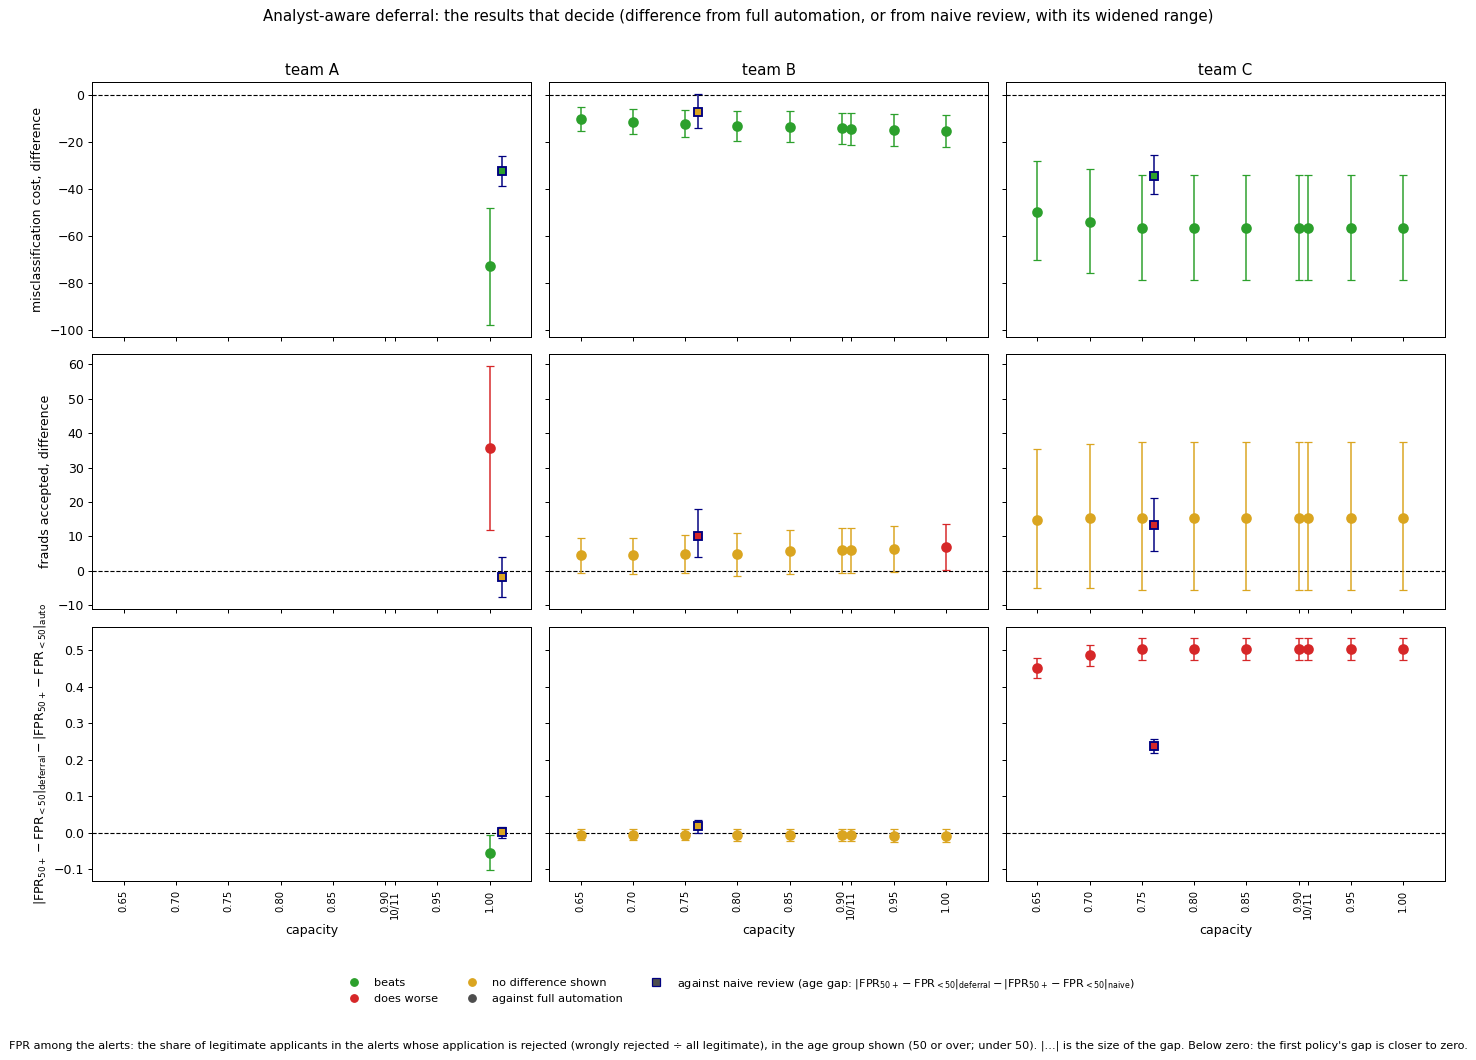

In [8]:
nb.section("P3-F10")

(1) The grid, drawn as for naive review, shows every deciding result of analyst-aware deferral; a second marker and colour show the three comparisons against naive review: team A at full capacity, and teams B and C at capacity 0.75. These are the results that decide the first part of the hypothesis: whether analyst-aware deferral beats full automation in every deciding result and naive review in all three comparisons. They are judged at the same capacities as naive review. The full sweep is descriptive: see [section 4](#4-descriptive-results) and `tables/P3-T5_full_sweep.csv`.

(2) On misclassification cost, analyst-aware deferral beats full automation with team A at full capacity and with teams B and C at every realistic capacity, and beats naive review with teams A and C. On frauds accepted, it does worse than full automation with teams A and B at full capacity, and shows no difference elsewhere. On the age gap, it beats full automation with team A, shows no difference with team B, and does worse with team C at every realistic capacity.

(3) Against full automation, the first part holds on misclassification cost and is refuted on frauds accepted and the age gap; against naive review, it is met on no measure (section 3.3).

**Age gap at capacity 0.75: FPR and FNR of each age group under each policy, teams B and C**

The graph below shows, for teams B and C at capacity 0.75, the FPR and FNR of each age group under each policy, because a smaller age gap can come from rejecting more applicants in both groups. FPR and FNR are among the alerts.

router's ranking quality: done in 15 s.
summary tables: done in 1 s.
descriptive figures: age groups, reviewers and Classifier h on the test month: done in 4 s.


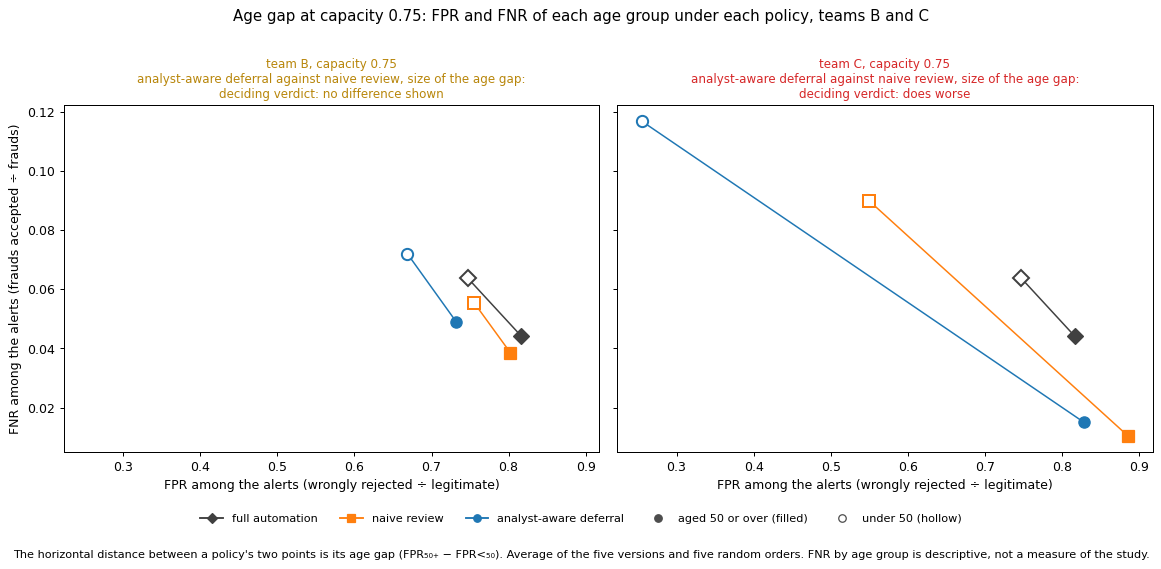

In [9]:
nb.section("P3-F11")

(1) It shows whether a smaller age gap comes from treating the two groups more alike or from rejecting more applicants in both groups, and what each costs in missed frauds. Descriptive.

(2) With team B, the three policies keep the two age groups about equally far apart; analyst-aware deferral rejects fewer legitimate applicants than the other two in both age groups, and accepts more frauds in both. With team C, both review policies widen the gap mainly by rejecting far fewer legitimate applicants under 50, at the cost of more of their frauds accepted, while applicants aged 50 or over are rejected about as often as under full automation or more often. Under analyst-aware deferral, the wider gap comes almost entirely from the group under 50. In neither team does a policy narrow the gap by rejecting more applicants in both groups.

(3) The verdict on the age gap is the deciding one, in the grid above; this graph only explains it.

<a id="33-the-verdict-on-the-hypothesis-measure-by-measure"></a>
### 3.3 The verdict on the hypothesis, measure by measure

As the project outline requires, every combination is reported, including those unfavourable to the hypothesis.

The project outline gives two conditions under which the hypothesis is refuted. The study applies each to every measure separately:
- **First condition: "deferral fails to outperform automation at any capacity level".** Read strictly: if analyst-aware deferral fails to beat full automation in at least one of its deciding results against full automation (team A at full capacity; teams B and C at each realistic capacity), the hypothesis is refuted on that measure.
- **Second condition: "naive HITL never falls below automation".** If no team under naive review does worse than full automation in any of its deciding results against full automation, the hypothesis is refuted on that measure.

The second part of the hypothesis is judged with two further rules: naive review with capacity exceeded (team C below full capacity) and naive review by reviewers who agree with the model (team B). The first part is also judged against naive review: analyst-aware deferral must beat naive review in all three comparisons on a measure.

The rule-outcome files `tables/P2-T3c_rule_outcomes.csv` and `tables/P3-T3c_rule_outcomes.csv` apply the rules of the design to the deciding results of section 3, one measure at a time. Each row is one rule and one measure, with its outcome and the teams and capacities that produce it.

**Misclassification cost.** Analyst-aware deferral beats full automation in every one of its deciding results against it, so the first refutation condition is not met. Against naive review it beats with team A at full capacity and team C at 0.75, but shows no difference with team B at 0.75, so the rule that it beats naive review in all three comparisons is not met. Under naive review, no team does worse than full automation in any deciding result: team A at full capacity beats it, team B shows no difference up to 10/11 and beats at 0.95 and 1, and team C shows no difference at 0.65 and 0.70 and beats from 0.75. The second refutation condition is therefore met: on misclassification cost, the hypothesis is refuted. Neither the rule for exceeded capacity (team C) nor the rule for reviewers who agree with the model (team B) is supported. Team C's bias rule shows no difference in misclassification cost at 0.75 against the same reviewers without it.

**Frauds accepted.** Analyst-aware deferral does worse than full automation with teams A and B at full capacity and shows no difference elsewhere, so the first refutation condition is met: on frauds accepted, the hypothesis is refuted. Against naive review, it shows no difference with team A and does worse with teams B and C at 0.75. Under naive review, teams A and B at full capacity do worse than full automation, where the reviewers themselves do worse than the classifier on the alerts they review, so the second refutation condition is not met. The rule for reviewers who agree with the model is supported on this measure (team B at full capacity), but not through the agreement. The cause is that the reviewers themselves do worse than the classifier on the alerts they review. Agreeing with the model moves team B towards the classifier: at full capacity, team B's excess of frauds accepted over full automation is about a fifth of team A's (0.21; long notebook, A.9). The rule for exceeded capacity is not supported (team C shows no difference at every realistic capacity).

**Size of the age gap.** Analyst-aware deferral beats full automation with team A at full capacity, shows no difference with team B and does worse with team C at every realistic capacity, so the first refutation condition is met: on the age gap, the hypothesis is refuted. Against naive review, it shows no difference with teams A and B and does worse with team C at 0.75. Under naive review, team C does worse than full automation at every realistic capacity, so the second refutation condition is not met, and the rule for exceeded capacity is supported; team C's age gap comes from its rule (section 4.6). The rule for reviewers who agree with the model is not supported: team B beats full automation at 0.65 and shows no difference elsewhere.

None of this shows what real reviewers, a better router or a cost of review would give.

<a id="4-descriptive-results"></a>
## 4. Descriptive results

<a id="41-the-capacity-range-over-which-each-policy-beats"></a>
### 4.1 The capacity range over which each policy beats

**Naive review: the capacity range over which it beats full automation, per team and measure, and the verdict at each capacity**

The graph gives, for each team and measure, the descriptive verdict at every capacity of the grid, with a tick where the average difference crosses zero. The crossing points and the verdicts of each version are in `tables/P2-T4_capacity_boundaries.csv`. Where a cell at a realistic capacity is also a deciding result, the deciding verdict in section 3 governs.

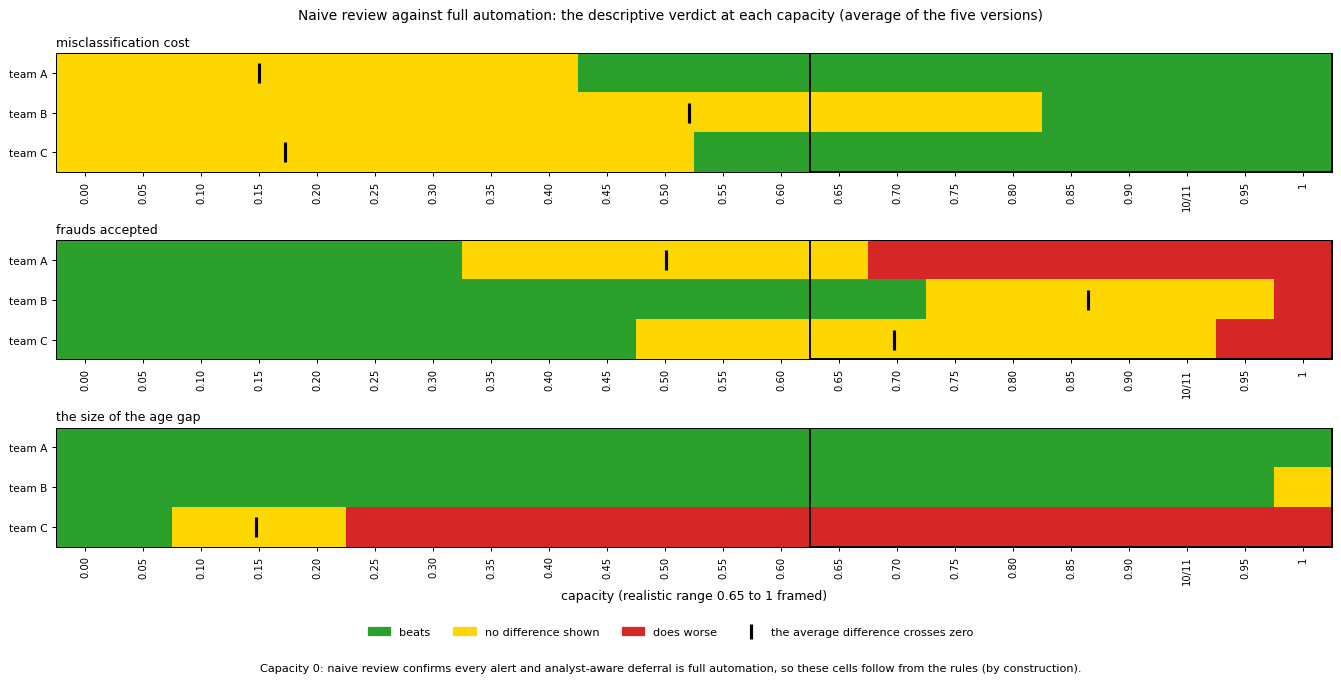

In [10]:
nb.section("P2-T4")

(1) For each team and measure, the capacities at which the policy beats full automation, does worse, or shows no difference. Descriptive: these ranges decide nothing. Where a cell at a realistic capacity is also a deciding result, the deciding verdict in section 3 governs.

(2) On misclassification cost, naive review never does worse than full automation, and beats it from some capacity upwards with every team: earliest with team A, latest with team B. On frauds accepted, it beats at low capacities, because the alerts beyond capacity are confirmed, and does worse near full capacity with every team. On the size of the age gap, it beats with teams A and B at almost every capacity, and does worse with team C over most of the grid, by team C's rule.

(3) The judging capacities of the project outline (team A at full capacity, teams B and C from 0.65 to 1) are fixed inputs to the design. These ranges show where each policy's advantage holds inside and outside them; they do not test the judging capacities.

**Analyst-aware deferral: the capacity range over which it beats full automation and naive review, per team and measure, and the verdict at each capacity**

The two graphs give, for each team and measure, the descriptive verdict at every capacity of the grid, with a tick where the average difference crosses zero. The crossing points and the verdicts of each version are in `tables/P3-T4_capacity_boundaries.csv`. Where a cell at a realistic capacity is also a deciding result, the deciding verdict in section 3 governs.

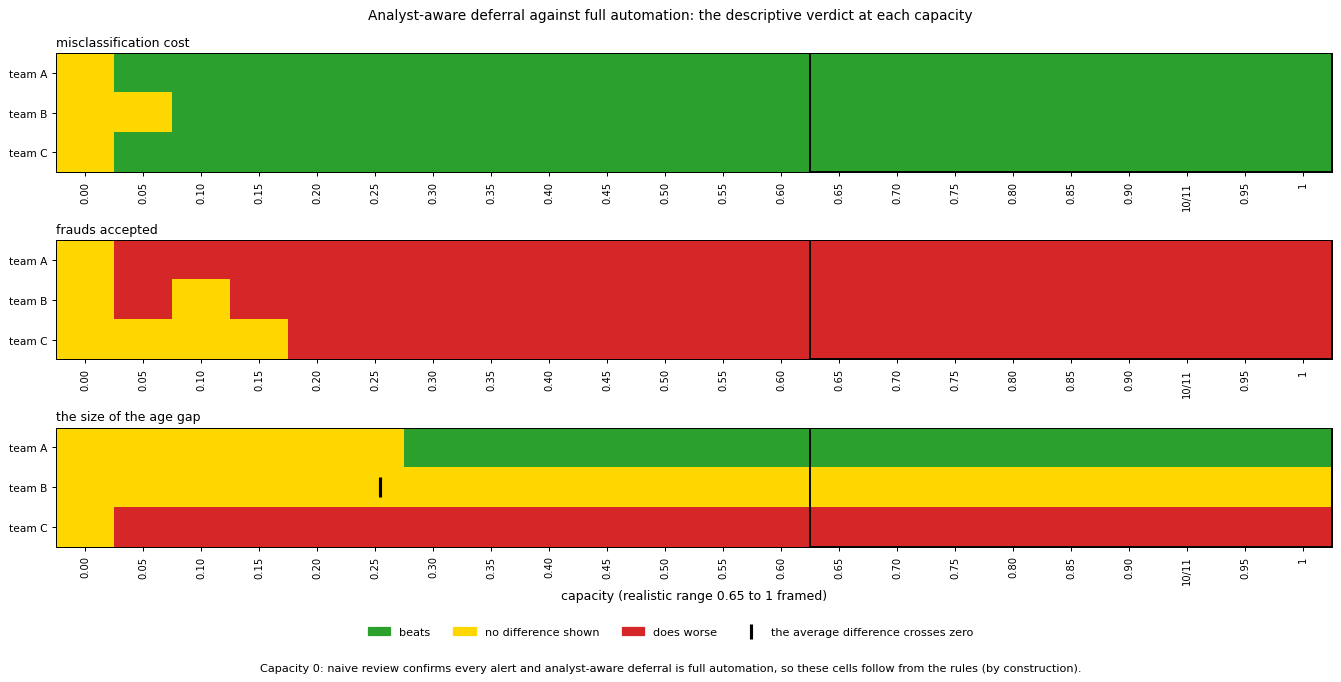

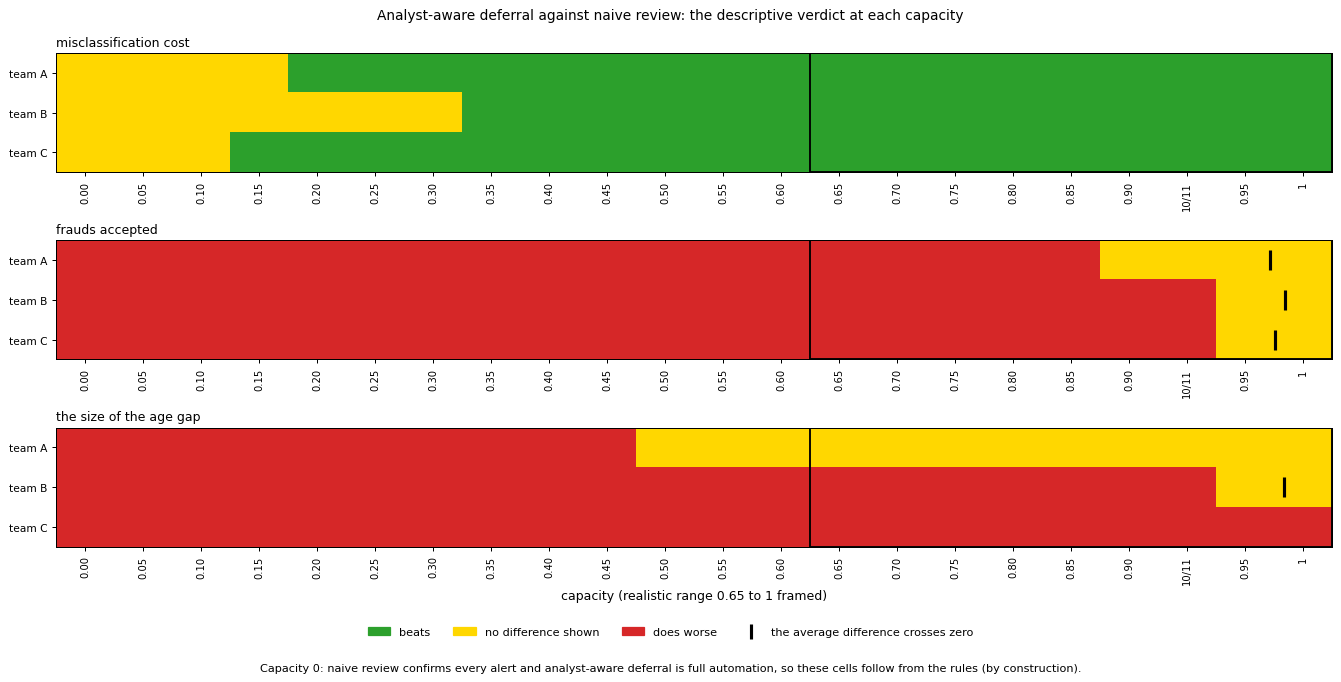

In [11]:
nb.section("P3-T4")

(1) For each team and measure, the capacities at which the policy beats full automation (and naive review), does worse, or shows no difference. Descriptive: these ranges decide nothing. Where a cell at a realistic capacity is also a deciding result, the deciding verdict in section 3 governs.

(2) On misclassification cost, analyst-aware deferral beats full automation with every team at almost every capacity, and beats naive review with every team from a low capacity upwards, earliest with team C and latest with team B. On frauds accepted, it does worse than full automation with every team over most of the grid, and worse than naive review at every capacity up to 0.85 with team A and up to 10/11 with teams B and C. On the size of the age gap, against full automation it beats with team A except at the lowest capacities, shows no difference with team B, and does worse with team C at every capacity above 0. Against naive review, its gap is the larger with team C at every capacity (at capacity 0 by construction), with team B at all but the highest, and with team A only below the middle of the grid.

(3) The judging capacities of the project outline (team A at full capacity, teams B and C from 0.65 to 1) are fixed inputs to the design. These ranges show where each policy's advantage holds inside and outside them; they do not test the judging capacities.

<a id="42-misclassification-cost-against-capacity"></a>
### 4.2 Misclassification cost against capacity

Full automation, the baseline, has a misclassification cost of 204.05, accepts 40 of the 711 frauds among the alerts (FNR 5.6%), and has an age gap of 0.0696 (FPR 0.8166 at 50 or over, 0.7470 under 50, among the alerts); its figures at every cost ratio, with ranges, are in `tables/P1-T2_baseline_by_cost_ratio.csv`.

**Analyst-aware deferral minus full automation, and minus naive review, misclassification cost, against capacity**

Each panel is one team. Blue is the difference from full automation, red the difference from naive review; for each, the thin lines are the five versions and the thick line their average with its 95% band. The realistic range, 0.65 to 1, is shaded. Below zero, analyst-aware deferral has the lower misclassification cost.

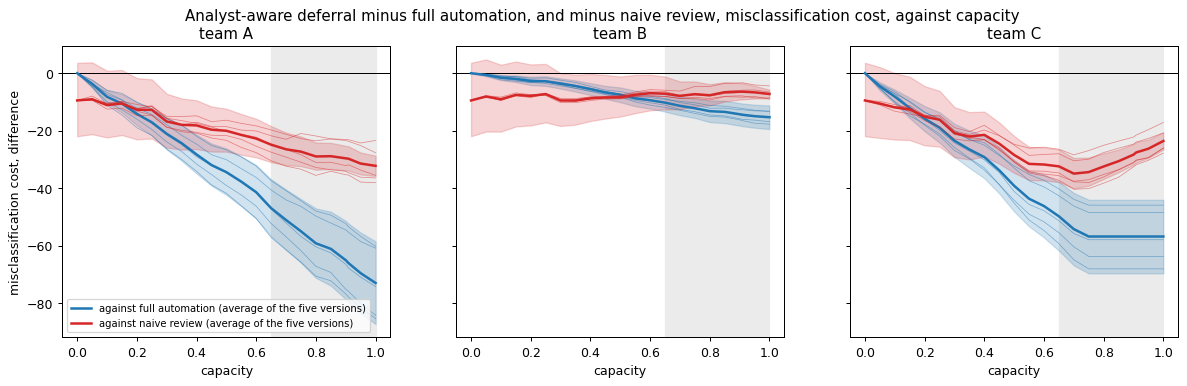

In [12]:
nb.section("P3-F1")

(1) It shows over the whole capacity grid where analyst-aware deferral's misclassification cost lies against full automation and against naive review, including capacities outside the realistic range. Descriptive.

(2) Analyst-aware deferral beats full automation for every team from the lowest capacities above zero, and beats naive review at every realistic capacity on the ordinary ranges.

(3) It supports the first part on misclassification cost against full automation; against naive review, the deciding result for team B shows no difference (section 3.2).

<a id="43-governance-effectiveness-monitoring"></a>
### 4.3 Governance effectiveness monitoring

The project outline proposes four indicators a bank could compute from its own review logs: reviewer override rate, capacity utilisation, cost avoided per review, and subgroup disparity. Criteria 1, 3 and 4, named below, are the project outline's criteria for appropriate oversight; section 4.8 lists all four and how this study treats each. A review place is one of the alerts a team's capacity allows it to review (capacity, section 2). The graphs show the four indicators for each team against capacity, averaged over the five versions, with 95% bands where a range exists. They are not defined at capacity 0, where nothing is reviewed. Two are adapted. Under naive review every review place is always used, so capacity utilisation is shown as the number of alerts per review place (1 ÷ capacity, the same for every team); under analyst-aware deferral, as the share of review places used. Cost avoided per review, against full automation, is the cost of one review at which review breaks even, in units of a missed fraud (criterion 3). For analyst-aware deferral, two more panels show criterion 1 as it turns out: on reviewed alerts, the share where the reviewer is right and full automation wrong, and the reverse.

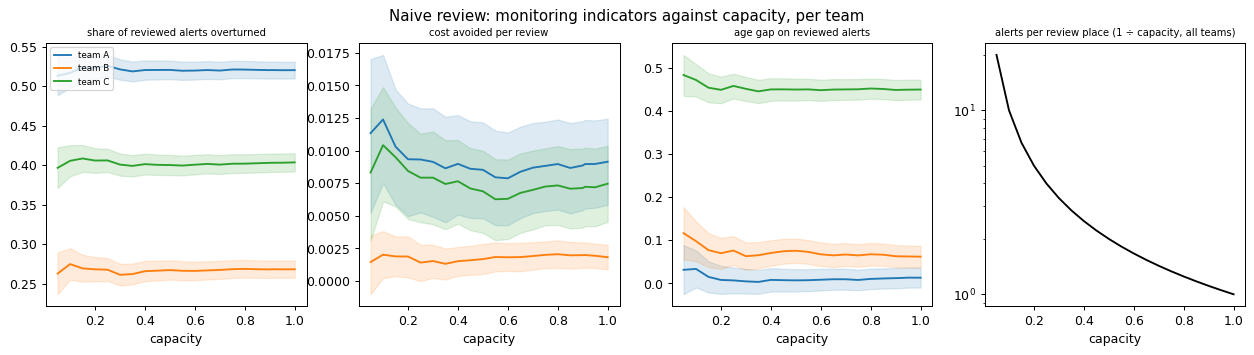

In [13]:
nb.section("P2-F6")

(1) These are the indicators the project outline proposes for detecting inappropriate oversight from review logs. No rule was fixed for them; they decide nothing.

(2) Team A overturns the most reviewed alerts, team B the fewest and team C in between, almost independently of capacity; team B's cost avoided per review is about a fifth of team A's; team C's age gap on reviewed alerts is much the largest.

(3) The indicators separate the three teams clearly, but no rule turns them into a verdict.

**Analyst-aware deferral: monitoring indicators against capacity, per team, with criterion 1 as it turns out**

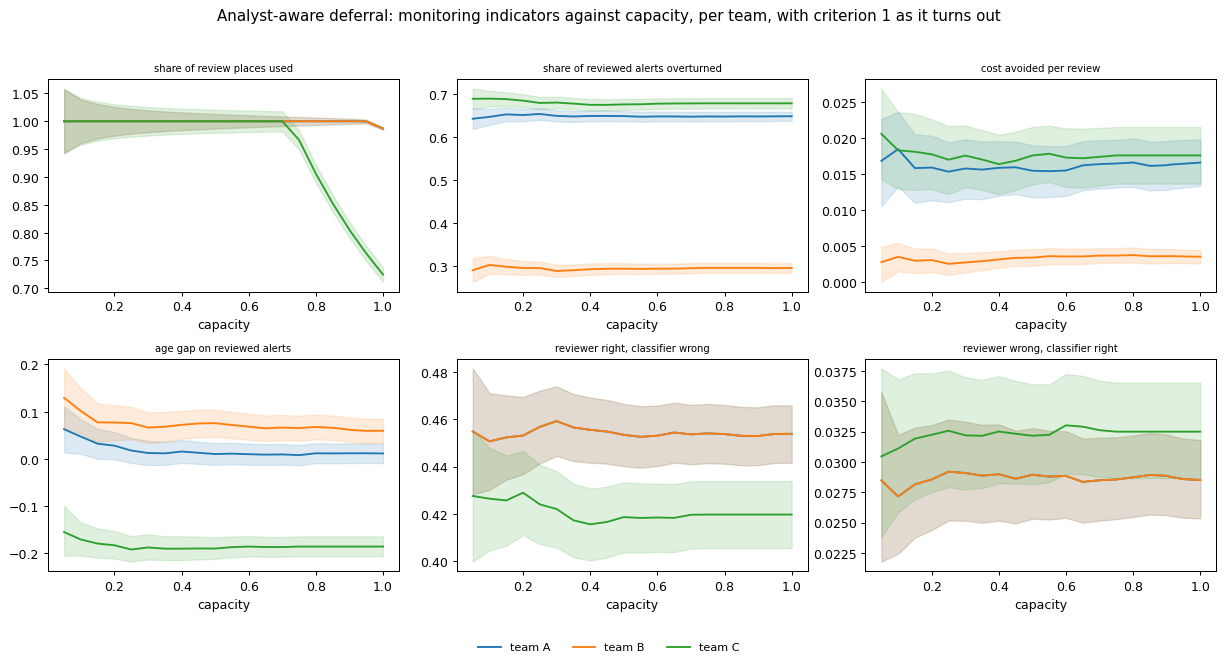

In [14]:
nb.section("P3-F5")

(1) As P2-F6, and it shows criterion 1 as it turns out: how often the reviewer is right where the classifier is wrong, and the reverse. Descriptive.

(2) Teams A and B use every review place except near full capacity, where they use slightly fewer; team C uses fewer from a lower capacity, because fewer of its alerts are routed to a reviewer. On reviewed alerts, the reviewer is right where the classifier is wrong far more often than wrong where the classifier is right.

(3) Criterion 1 holds on the reviewed alerts as it turns out; the indicators decide nothing.

No rule was fixed for these indicators, so they carry no verdict and support no conclusion about detecting inappropriate oversight before it fails. They show what such indicators look like in this simulation. Criterion 4 shows only through the override rate. Two readings follow from the rules, and both hold in this run: under naive review, the load is the same for every team at a given capacity, and team B's cost avoided per review is about a fifth of team A's.

<a id="44-the-reviewers-against-classifier-h"></a>
### 4.4 The reviewers against Classifier h

The graph shows how good each of the 50 reviewers is compared with Classifier h, on the alerts of the test month.

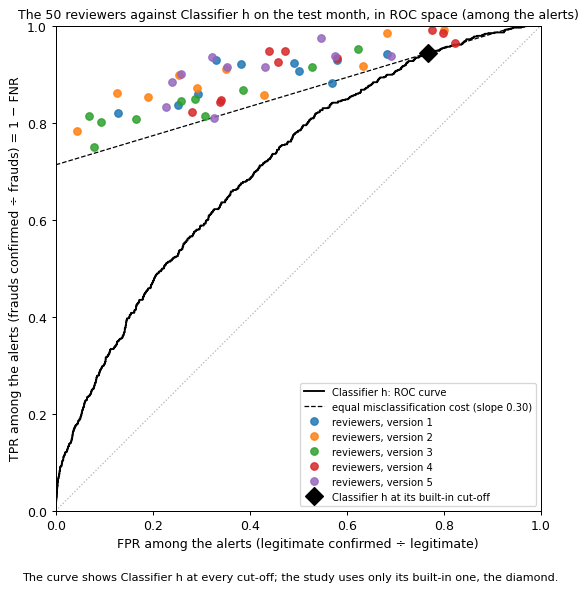

In [15]:
nb.section("P2-T1")

(1) Criterion 1 of the project outline asks whether the reviewer is more likely than the model to be correct. The graph shows how far that holds for each reviewer on its own, before any team rule or routing. A reviewer above the dashed line beats Classifier h on misclassification cost as h is set. A reviewer above h's curve does better than h could at any cut-off. Descriptive.

(2) Every reviewer lies above Classifier h's curve: on its own, each separates frauds from legitimate applicants better than h could at any cut-off. All but two lie above the dashed line, so they have a lower misclassification cost than h as it is set; the other two lie just below it. The reviewers differ widely in how many legitimate applicants they reject.

(3) It decides nothing; section 4.3 shows criterion 1 as it turns out on the alerts actually reviewed.

<a id="45-who-gets-a-reviewer-access-by-age-group"></a>
### 4.5 Who gets a reviewer: access by age group

**Team C: share of alerts sent to a reviewer against capacity, by age group, analyst-aware deferral and naive review**

For teams A and B, both age groups reach a reviewer in proportion to capacity under both policies; their lines lie on naive review's diagonal, so they are not drawn. The graph shows team C: solid lines for analyst-aware deferral, dashed for naive review; red for applicants aged 50 or over, blue for those under 50.

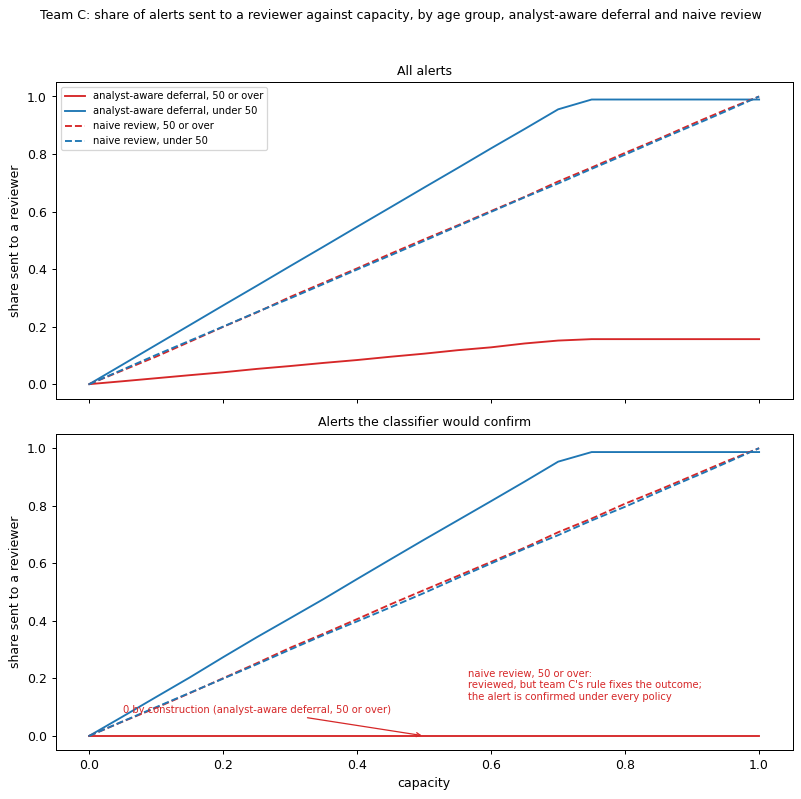

In [16]:
nb.section("P3-F9")

How the router chooses where each alert goes is in section 4.8.

(1) It shows whether older and younger applicants get the same access to a reviewer under each policy, which bears on fairness exposure beyond the outcome.

(2) Under naive review, both age groups reach a reviewer in proportion to capacity. Under analyst-aware deferral with team C, from a capacity of 0.75 upwards, applicants aged 50 or over reach a reviewer only about one time in six (16%), while applicants under 50 almost always do (99%); below 0.75 both shares are lower, and the older group's never exceeds 16%. None of the older applicants whose alert the classifier would confirm ever reaches a reviewer: team C's rule would reject them whatever the reviewer decided, so the routing sends them straight to the classifier.

(3) With a biased team, analyst-aware deferral quietly denies most older applicants a human review, although the outcomes may look equal on average. This decides nothing.

In the table below, within each age group, the policies keep the same order as among the alerts, because each group's denominator is fixed.

In [17]:
nb.section("P3-T10")

**FPRs on every application of the test month, descriptive; applications the Alert Model did not flag count as accepted (at the deciding comparisons; average of the five versions and five random orders)**

<a id="46-team-cs-bias-against-capacity"></a>
### 4.6 Team C's bias against capacity

**Naive review: FPRs by age group for teams C and A against capacity, and how team C's bias changes between capacity 0.75 and full capacity**

The project outline's question is whether a bias compounds or cancels when capacity is exceeded. The measure is the difference between teams C and A at capacity 0.75, minus the same difference at full capacity, on three figures: the signed age gap, the number of wrongly rejected applicants aged 50 or over, and misclassification cost.

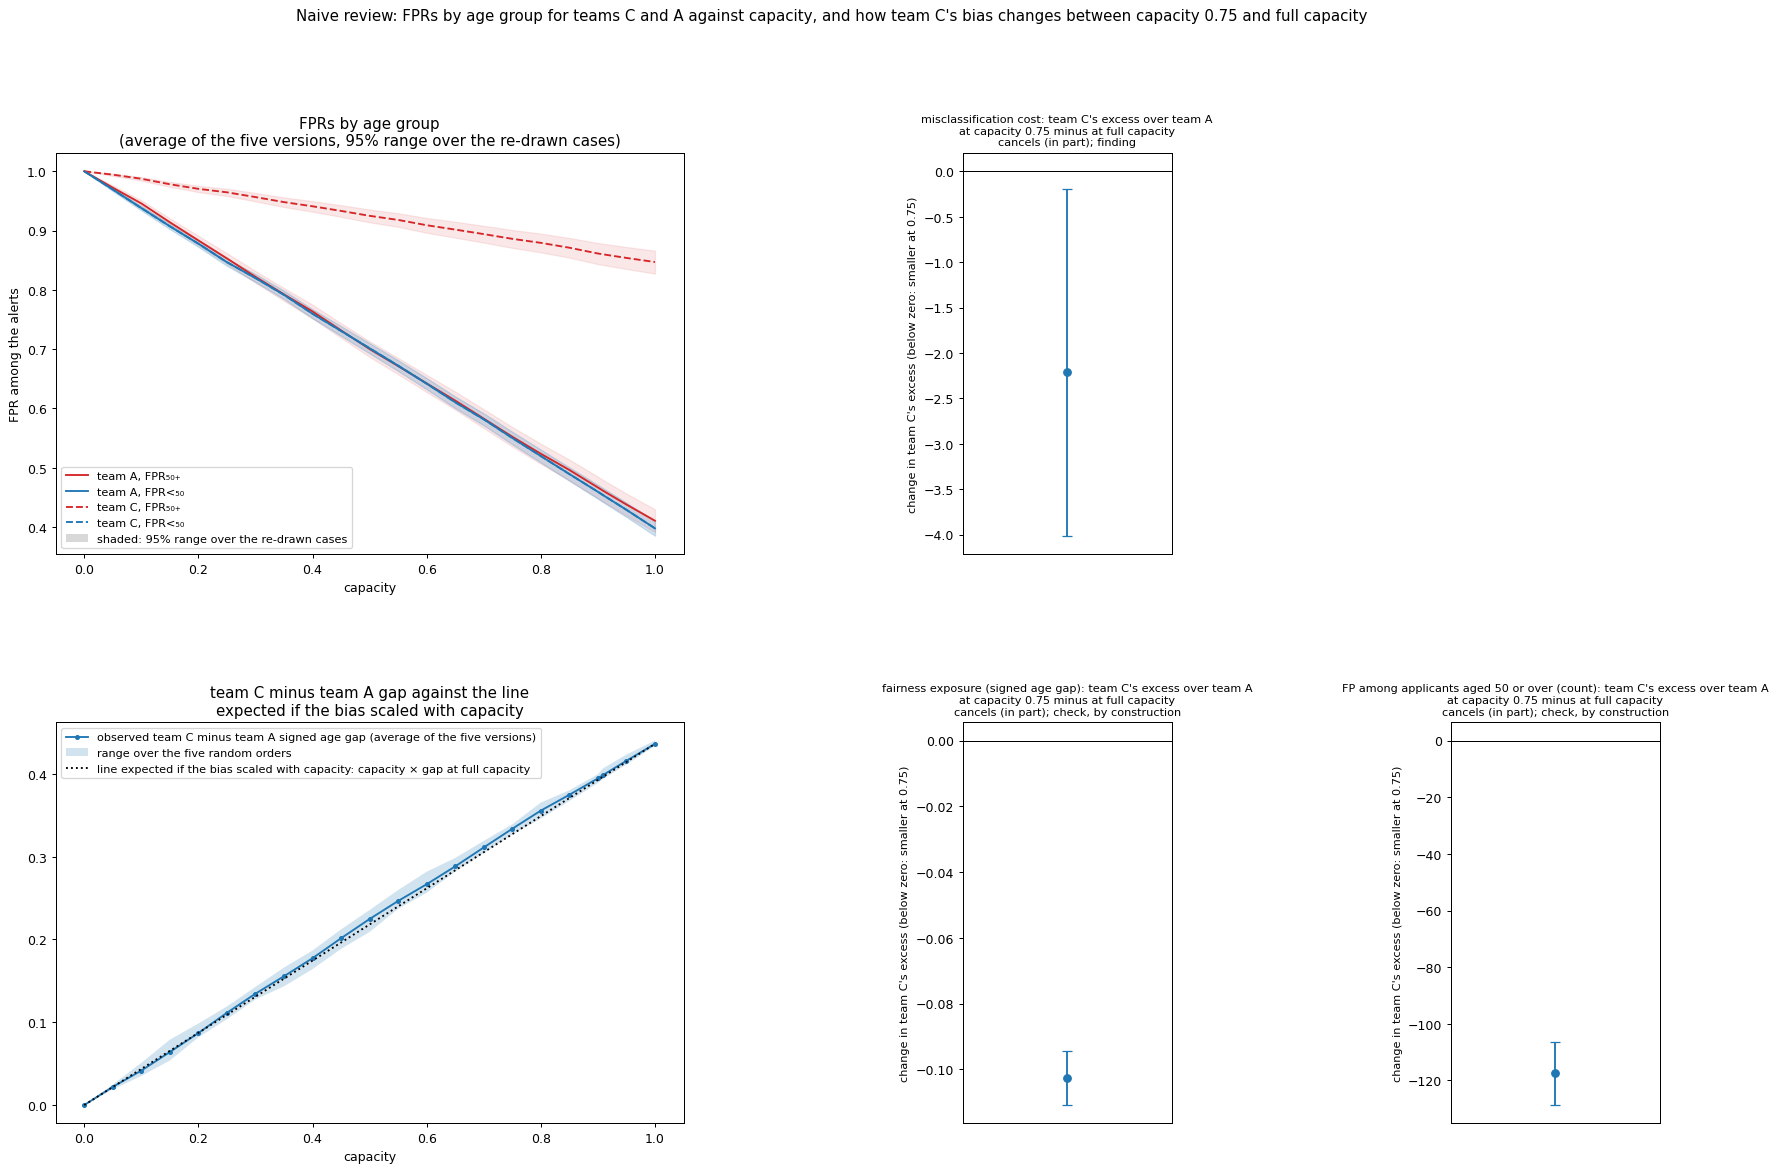

In [18]:
nb.section("P2-F5")

(1) **How to read it.** At capacity 0 no alert is reviewed, so every alert is confirmed and every application among the alerts is rejected: both age groups start at an FPR of 1. As capacity rises, team A lowers both groups' FPR together. Team C lowers the FPR of applicants under 50 in the same way, but that of applicants aged 50 or over much less: at full capacity, team C's age gap is about 0.44 larger than team A's, so legitimate applicants aged 50 or over are wrongly rejected about 44 percentage points more often, relative to those under 50, than with the control team. In the three small panels, the last line of each title reads the change: "cancels (in part)" if its whole range is below zero (team C's excess is smaller at 0.75 than at full capacity), "compounds" if its whole range is above zero, and "additive" if the range includes zero.

(2) **Overload does not make team C's bias worse; it hides it.** Team C's excess over team A shrinks in proportion to capacity: the observed gap follows the line expected if the bias scaled with capacity. Between full capacity and 0.75, the excess age gap falls by 0.10 (95% range 0.09 to 0.11), and the excess of wrongly rejected applicants aged 50 or over by 117 (106 to 129). Both follow from the rules: every alert beyond capacity is confirmed whoever the team is, so the overload masks team C's rule rather than correcting it. A smaller gap reached this way is not good news; it comes from rejecting more legitimate applicants of every age.

(3) **The one finding is on misclassification cost, and it is small.** Team C's extra cost over team A is 2.2 lower at 0.75 than at full capacity (95% range 0.2 to 4.0), so the verdict is "beats" and the reading "cancels (in part)"; only three of the five versions show it, and the other two read "additive". None of this says anything about real reviewers.

<a id="47-where-the-difference-against-naive-review-comes-from"></a>
### 4.7 Where the difference against naive review comes from

**Analyst-aware deferral minus naive review, split into the alerts left to the classifier and the alerts reviewed, on both measures, with ranges and verdicts**

The graph gives, for team A at full capacity and teams B and C at capacity 0.75, the part from the alerts analyst-aware deferral leaves to the classifier and the part from the alerts it sends to a reviewer, on misclassification cost and on frauds accepted. Each marker is the average of the five versions, with its 95% range, coloured by its verdict and labelled with its value. These results are descriptive and decide nothing. They are read from the run's full results by their key columns, with nothing recomputed.

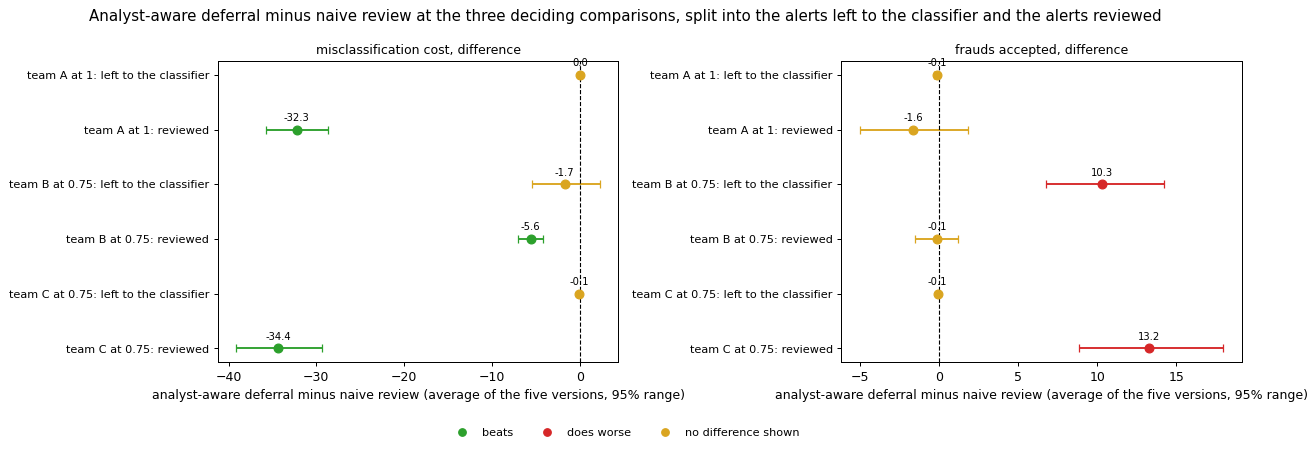

In [19]:
nb.section("rows-split")

(1) It shows whether analyst-aware deferral's difference from naive review comes from the alerts it reviews or from the alerts it leaves to the classifier, which naive review would confirm beyond capacity. Only the first bears on routing to the right reviewer. Descriptive.

(2) In the three deciding comparisons, the advantage on misclassification cost lies in the alerts reviewed.

(3) Team B's extra frauds accepted lie in the alerts left to the classifier, so they reflect how the alerts not reviewed are treated, not the routing; team C's lie in the alerts reviewed. The verdict of the whole difference is the deciding verdict of section 3.2; the verdicts of the parts are descriptive.

The split does not separate the router's choice of alerts and reviewers from the way the alerts it does not review are treated. Its results are descriptive and decide nothing; the graph above gives both parts on both measures, with the 95% ranges and verdicts.

<a id="48-how-analyst-aware-deferral-routed-the-alerts-and-how-well-the-router-ranks"></a>
### 4.8 How analyst-aware deferral routed the alerts, and how well the router ranks

The project outline proposes that a case should reach a human only if (1) the reviewer is more likely than the model to be correct; (2) the volume routed fits the actual review capacity; (3) the misclassification cost avoided (the project outline's "expected loss avoided") exceeds the cost of review; (4) the reviewer has the information and time to disagree with the model. In this study:
- **Criterion 1** is built into analyst-aware deferral as the router sees it: a reviewer takes an alert only if the router's estimate of the reviewer being right is strictly above the classifier's confidence. Whether it holds in fact is measured (section 4.3).
- **Criterion 2** is built in: never more alerts are reviewed than capacity allows.
- **Criterion 3** is measured, not enforced: the cost avoided per review is shown as the cost of one review at which review breaks even (section 4.3). No cost of review is modelled.
- **Criterion 4** cannot be observed directly in a simulation without time pressure; it shows only through how often reviewers overturn the alert (section 4.3).

**Analyst-aware deferral: how the alerts are allocated against capacity, and how the reviewed alerts are shared among the ten reviewers**

The first graph shows, at capacities 1, 10/11, 0.75 and 0.65, the share of the 4,457 alerts routed to a reviewer, routed to the classifier, and decided by the classifier because the pool of review places is full, counted by the branch of the routing trees and averaged over the five versions and random orders. Teams A and B share one routing; team C has its own. It shows how the share decided by the classifier because the pool is full grows as capacity falls (criterion 2). The second graph shows, for teams A and B at capacities 1 and 0.75, each reviewer's share of the reviewed alerts, from the busiest to the least busy; a flat line would be an even split. The counts per team, version, random order and capacity are in `tables/P3-T1a_routing.csv`.

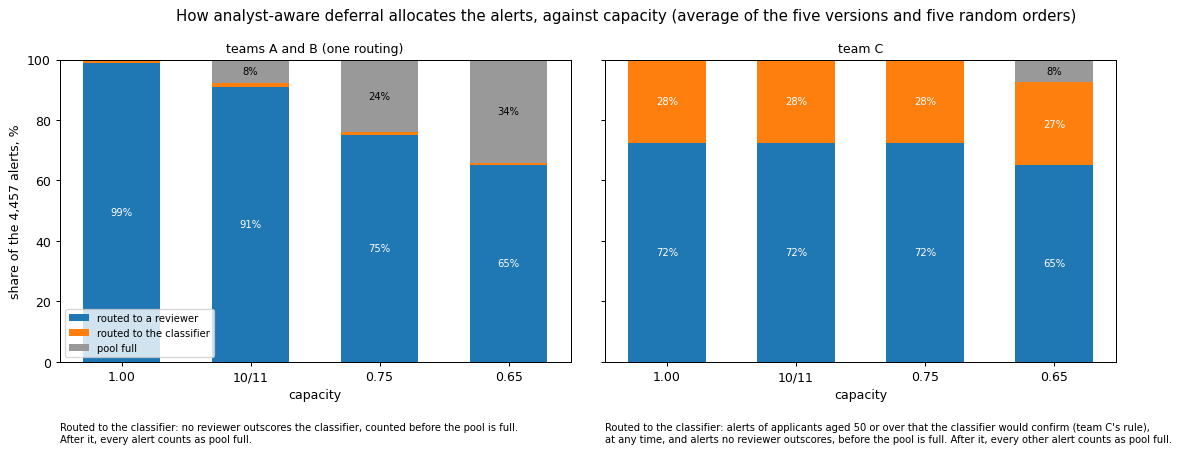

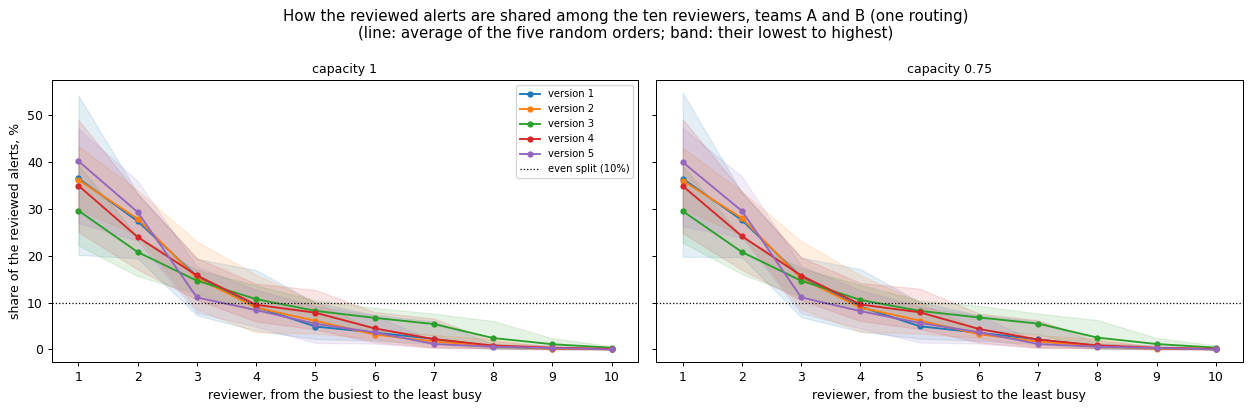

In [20]:
nb.section("P3-T1")

**How well the router tells apart the alerts each reviewer gets right from those the reviewer gets wrong**

Analyst-aware deferral relies on the framework's **OvA Classifiers**, one model per reviewer, here called the router, to estimate how likely each reviewer is to decide an alert correctly. The router's models are trained on the decisions of this study's reviewers by the framework's own procedure, including its settings search; by default this notebook refits them from the settings that search chose (section 2). How well these estimates separate the alerts a reviewer decides correctly from those the reviewer gets wrong is measured as an area under the ROC curve: 0.5 is chance and 1 is perfect. The graph shows, for each team version, the average, lowest and highest of this figure over the version's 50 models (its ten reviewers, five training shuffles each), on the test month beside the previous month. The previous month is the one on which the router's models were validated and their settings chosen, so its figures are not measured on unseen data; only the test month's are.

(Each figure is the area under the ROC curve with legitimate applicants weighted 0.057 and frauds 1. The figure for each single model is in the accompanying table file.)

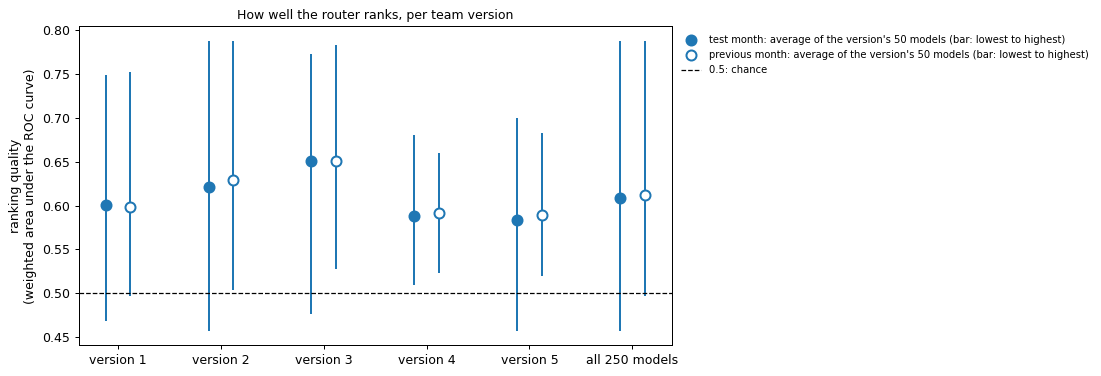

In [21]:
nb.section("P3-T1r")

Averaged over each version's models, the router ranks only a little better than chance, and about equally in the two months; 6 of the 250 single models are at or below chance on the test month, and 1 on the previous month. Because the previous month is the router's validation month, the agreement between the two months says little about how stable the ranking is. The router ranks the reviewers' correctness only weakly. Analyst-aware deferral is therefore tested as the framework implements it, not as the best possible router would do.

<a id="49-other-cost-ratios"></a>
### 4.9 Other cost ratios

**Naive review: misclassification-cost verdict against full automation at each cost ratio and capacity**

Each grid shows, for each team, the descriptive misclassification-cost verdict against full automation at every capacity (across) and cost ratio (down): green beats, red does worse. Away from 0.057, neither full automation nor the reviewers (nor, for analyst-aware deferral, the router) is re-tuned for the cost ratio, so every "beats" there holds only "against an automation baseline not re-optimised for this cost ratio".

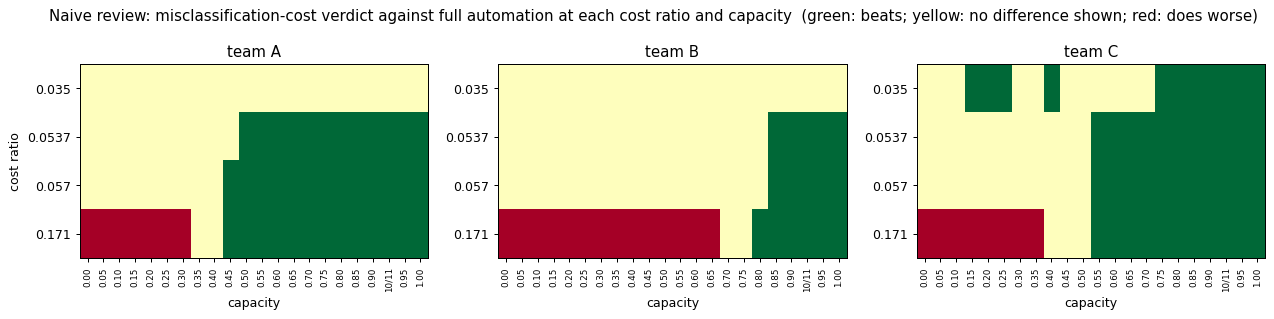

In [22]:
nb.section("P2-F7")

(1) The cost ratio is a parameter of the study. The graph shows whether naive review's verdict on misclassification cost holds away from the main ratio, against a baseline not re-tuned for it. Descriptive.

(2) Where naive review beats full automation with a team at the main cost ratio, it also beats at the highest ratio and, with one exception for team A, at the ratio just below the main one; at the lowest ratio most of these turn to no difference, and at the highest every team does worse at low capacities.

(3) No naive-review result is shown to beat full automation robustly across cost ratios, because full automation is not re-tuned for each ratio. The run's tables label a team and capacity "conditional" if it beats full automation at one or more of the other cost ratios and does worse at none, and "not robust" if it beats at one or more and does worse at one or more. Even where a team beats full automation at all four ratios (team C at the higher capacities), the label is "conditional"; team C is labelled "not robust" at capacities 0.15 to 0.25.

**Analyst-aware deferral: misclassification-cost verdict against full automation at each cost ratio and capacity**

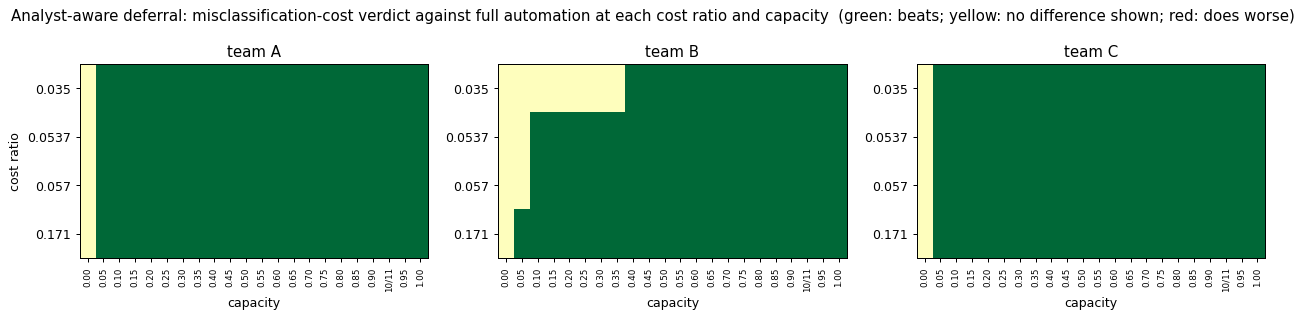

In [23]:
nb.section("P3-F6")

(1) As P2-F7, for analyst-aware deferral. Descriptive.

(2) Analyst-aware deferral beats full automation with teams A and C at every capacity above 0, at all four cost ratios. With team B, it beats only from a middle capacity upwards; below that, it shows no difference at the lowest cost ratio, and at the lowest capacity above zero it beats only at the highest ratio.

(3) Every team is labelled "conditional" at every capacity above 0: it beats full automation at one or more of the other cost ratios and does worse at none. No result is labelled "not robust" (beats at one or more, does worse at one or more), and none is shown against a baseline re-tuned for the cost ratio.

Every team, capacity, version and cost ratio, with all measures: `tables/P2-T5_full_sweep.csv`, `tables/P3-T5_full_sweep.csv`.

<a id="5-limitations-and-risks"></a>
## 5. Limitations and risks

<a id="51-limitations"></a>
### 5.1 Limitations

- **The reviewers are simulated.** Each makes one fixed decision per alert; there is no fatigue, time pressure or learning, and exceeding capacity changes only what happens to the alerts beyond it. The project outline's criterion 4 shows only through the override rate.
- **No cost of review is modelled.** Cost avoided per review is shown as the break-even cost instead.
- **One alert model, one test month:** 4,457 alerts, 711 of them frauds. Frauds the Alert Model did not flag are outside the study.
- **The cost ratio is implied, not observed.** The data suggest a ratio of roughly 0.03 to 0.045; of that range only 0.035 is tested. Away from 0.057, neither full automation, the reviewers nor the router is re-tuned, and how much better a re-tuned automation would do is not measured.
- **The reviewers are regenerated**, without any weight on age and fitted on four months; they are not the dataset's original reviewers.
- **Team B's 4 in 5** is the author's judgement, not observed behaviour; other values would give other results for team B. **Team C's bias is a rule**, not a model of how bias arises in people.
- **The router is weak.** It ranks the reviewers' correctness only weakly, and some of its models are at or below chance. A router that fits the reviewers less well puts analyst-aware deferral at a disadvantage.
- **The routing's own effect is not separated** from how the alerts not reviewed are treated (section 4.7).
- **Capacity is modelled as one shared pool** of review places, with the classifier unlimited, and the router sends most of the work to a few reviewers. With teams A and B at full capacity, the two busiest of the ten reviewers take between about two in five and four in five of the reviewed alerts, depending on the version and the random order. In more than half of the runs at least one reviewer takes none (section 4.8). Which reviewers are favoured changes with the router's training shuffle. No real team could absorb such a split, and fatigue is not modelled, so analyst-aware deferral is shown under conditions more favourable than a real team would offer.
- **The alerts are taken in a random order**, not by score, so that the policies are compared like for like; under analyst-aware deferral the order affects which alerts are reviewed, and its effect is part of the spread over the random orders.
- **The ranges cover which cases fell in the test month**, not the policy's own randomness, which is shown as the range over random orders. The rule that a team beats or does worse when all five versions agree, or else by their average, makes the 5% chance of a false finding approximate. The deciding results of the two policies are adjusted separately, so across both together that chance is above 5%.
- **Capacity steps by 0.05**, so every crossing is located only to within that step.
- **The implementation was checked during the study.** The checks are not repeated in this notebook.
- The project outline's own limitation on the author's dual role as project owner and stakeholder stands.

<a id="52-risks"></a>
### 5.2 Risks

The risk named in the project outline, that the pre-trained models might not run well on the available Apple Silicon machine, did not stop any part of the study: the study's own computation ran on the project's machine. The outputs shown in this notebook were computed on free Google Colab, by the run that produced this copy. Run time and memory are in the technical section.

<a id="appendix"></a>
## Appendix

Descriptive results left out of the short notebook; they decide nothing.

<a id="a1-full-automation-the-baseline"></a>
### A.1 Full automation, the baseline

**Full automation and "confirm every alert": the three measures at each cost ratio**

Full automation is the baseline every other policy is compared with, alert by alert. The table gives its three measures at each cost ratio, each with a 95% range from 1,000 re-draws of the cases. Beside it is a reference figure, not a policy: "confirm every alert", where every flagged application is rejected.

In [24]:
nb.section("P1-T2")

*FPR among the alerts.*

Full automation: its FNR is 5.6%: of the frauds among the flagged applications, 5.6% were accepted and 94.4% rejected. The decisions do not change with the cost ratio; only misclassification cost does.

**Full automation and "confirm every alert": the three measures against the cost ratio**

The graph draws the same figures against the cost ratio, with 0.057 marked. Away from 0.057 the classifier's decisions are kept as they are, not re-optimised for the cost ratio.

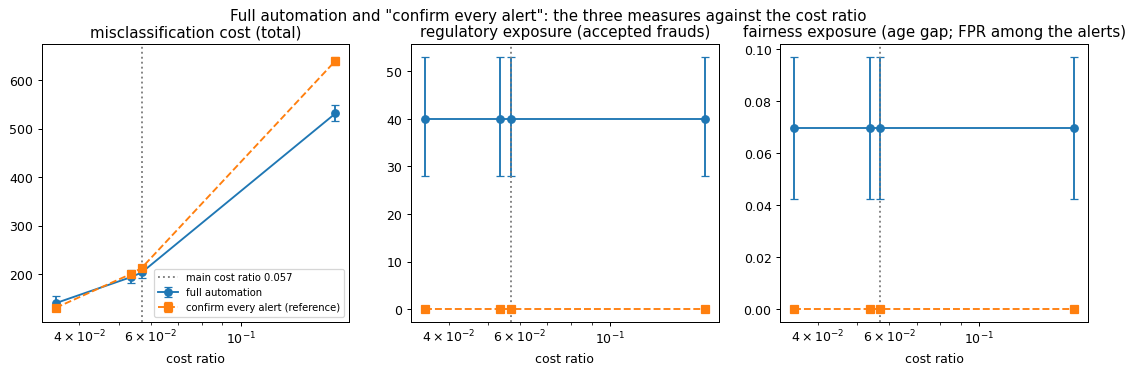

In [25]:
nb.section("P1-F1")

(1) Full automation is the reference for every comparison. The graph shows how its misclassification cost moves with the cost ratio while its decisions stay the same. Descriptive.

(2) Full automation's frauds accepted and age gap do not change with the cost ratio, because its decisions do not; its misclassification cost rises with the ratio. Confirming every alert has the lower misclassification cost only at the lowest cost ratio.

(3) It sets the reference and decides nothing.

<a id="a2-misclassification-cost-against-capacity"></a>
### A.2 Misclassification cost against capacity

**Naive review minus full automation, misclassification cost, against capacity**

Each panel is one team. The thin lines are the five versions, the thick line their average with its 95% band; the realistic range, 0.65 to 1, is shaded, and the points where the average crosses zero are marked. Below zero the policy has the lower misclassification cost.

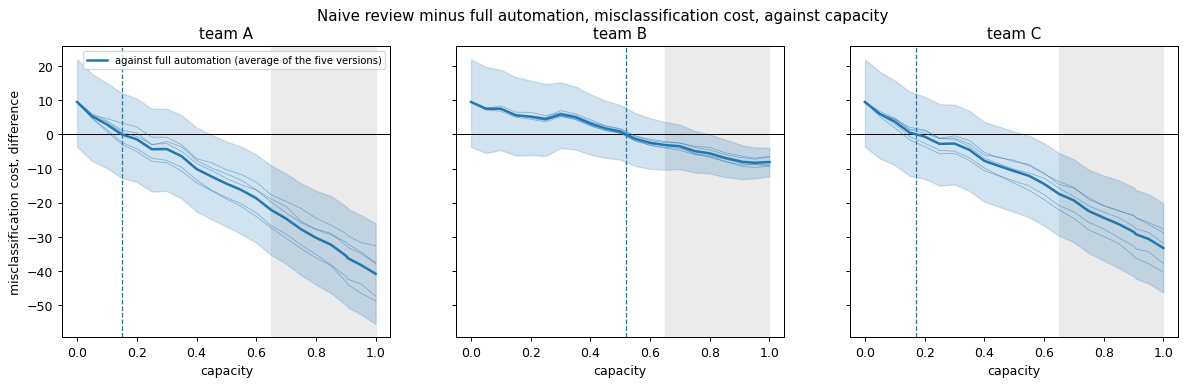

In [26]:
nb.section("P2-F1")

(1) It shows over the whole capacity grid where naive review's misclassification cost lies against full automation, including capacities outside the realistic range. Descriptive.

(2) Naive review does not do worse than full automation with any team at any capacity. On the average of the five versions, it beats full automation from some capacity upwards with every team: first with team A, then with team C, and with team B only at the higher capacities.

(3) On misclassification cost naive review never falls below full automation, which refutes the second part on this measure (section 3.3).

**Naive review minus full automation, misclassification cost, split into the reviewed alerts and the alerts beyond capacity**

Naive review can differ from full automation for two reasons: on the alerts the team reviews, the team decides instead of the classifier; on the alerts beyond capacity, every alert is confirmed instead. The bars split the misclassification-cost difference into these two parts, by team and capacity, as point values (average of the five versions). The part beyond capacity is the same for teams B and C, which leave the same alerts unreviewed.

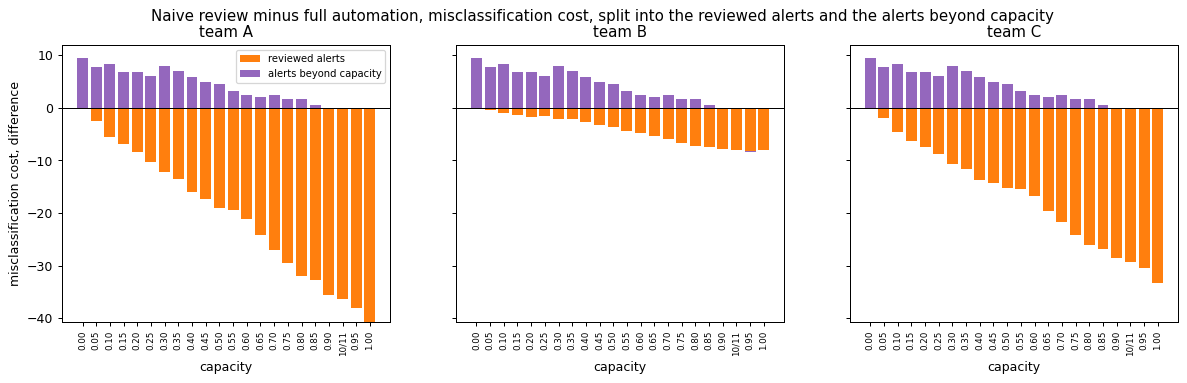

In [27]:
nb.section("P2-F4")

(1) It separates what the reviewers' own decisions contribute from what the confirmation of alerts beyond capacity contributes, which is the mechanism behind "capacity exceeded". Descriptive.

(2) The prediction that the alerts beyond capacity raise misclassification cost held in point value at the realistic capacities except 0.95; the alerts beyond capacity are not shown to change misclassification cost in either direction. The reviewed alerts lower it, by much more for team C than for team B.

(3) In this study, exceeded capacity does not by itself make naive review worse than full automation on misclassification cost.

**Where the difference in misclassification cost between analyst-aware deferral and naive review comes from, at each capacity: alerts reviewed and alerts left to the classifier**

Analyst-aware deferral and naive review differ in two ways at once: which alerts are reviewed and by whom, and what happens to the alerts that are not reviewed (the classifier decides them under analyst-aware deferral; naive review confirms them, rejecting the application). The bars split the misclassification-cost difference into these two parts, by team and capacity: the alerts analyst-aware deferral leaves to the classifier, and the alerts it sends to a reviewer. The two parts add up to the whole difference.

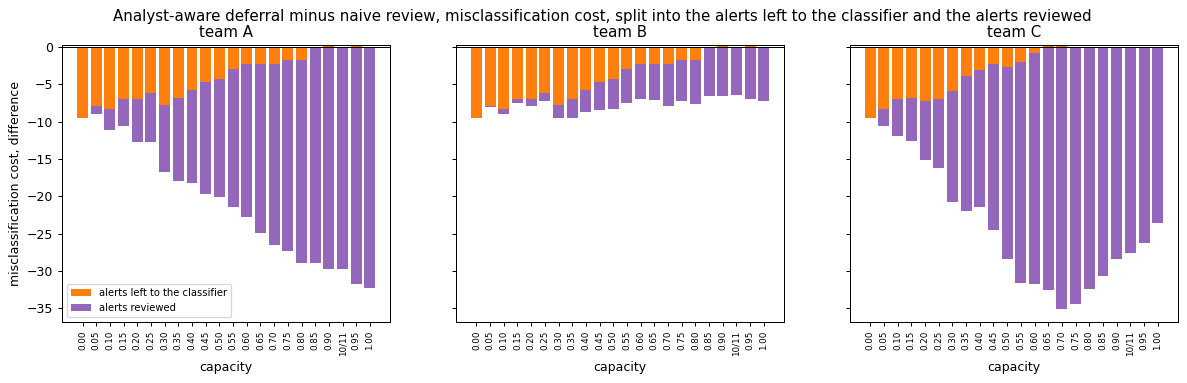

In [28]:
nb.section("P3-F4")

(1) It splits analyst-aware deferral's difference from naive review, at every capacity, into the alerts it reviews and the alerts it leaves to the classifier, which naive review would confirm. Descriptive.

(2) At the lowest capacities, the part left to the classifier is as large as the reviewed part or larger.

(3) Only the reviewed part bears on routing to the right reviewer. The split at the deciding comparisons is in section 4.7; it decides nothing.

<a id="a3-frauds-accepted-against-capacity"></a>
### A.3 Frauds accepted against capacity

**Naive review minus full automation, frauds accepted, against capacity**

The same layout as for misclassification cost, for the number of frauds accepted. At capacity 0, naive review confirms every alert and so accepts no fraud; analyst-aware deferral is full automation.

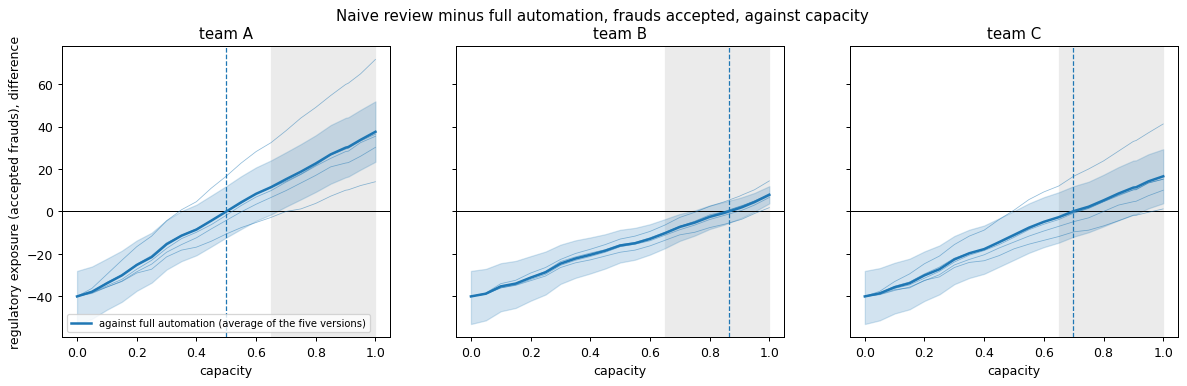

In [29]:
nb.section("P2-F2")

(1) Frauds accepted is the regulatory measure. The graph shows where naive review accepts more or fewer frauds than full automation across capacity. Descriptive.

(2) At low capacity naive review accepts fewer frauds than full automation, because the alerts beyond capacity are confirmed; as capacity rises the reviewers' own decisions take over, and on the ordinary ranges, at full capacity every team accepts more frauds than full automation (team A over most of the realistic range). For team C at full capacity, the deciding verdict shows no difference (sections 3.1 and 4.1).

(3) On this measure naive review can fall below full automation, through the reviewers' own decisions rather than through exceeded capacity (section 3.3).

**Analyst-aware deferral minus full automation, and minus naive review, frauds accepted, against capacity**

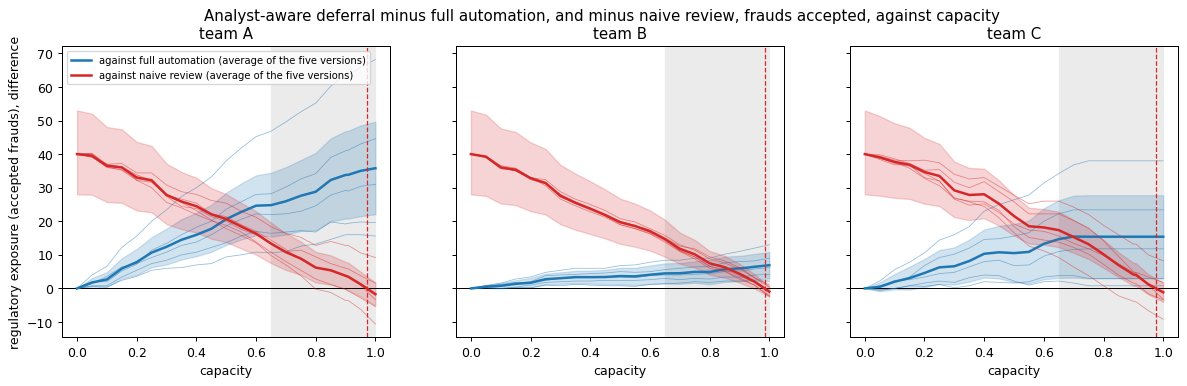

In [30]:
nb.section("P3-F2")

(1) As P2-F2, for analyst-aware deferral, against both other policies. Descriptive.

(2) On the ordinary ranges, analyst-aware deferral accepts more frauds than full automation with every team at every realistic capacity, and more than naive review except at the highest capacities, where team A stops sooner than teams B and C.

(3) On frauds accepted the first part is refuted (section 3.3).

<a id="a4-age-gap-against-capacity"></a>
### A.4 Age gap against capacity

**Naive review minus full automation, size of the age gap, against capacity, with the overall FPR**

The same layout, for the size of the age gap, with the policy's overall FPR on a second axis. The second axis matters for naive review: alerts beyond capacity are rejected in both age groups alike, which pulls the gap towards zero. Where naive review's gap is smaller while it rejects more applicants overall, the study reports "gap narrowed by rejecting more applicants in both groups", not a fairness improvement.

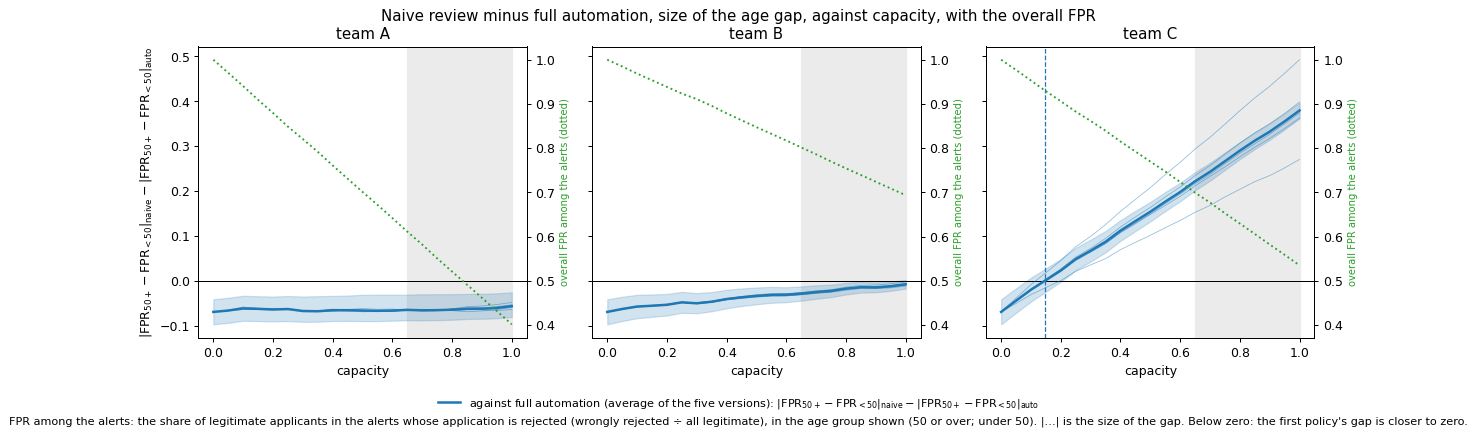

In [31]:
nb.section("P2-F3")

(1) The age gap is the fairness measure. The overall FPR is shown beside it because a gap can narrow when more applicants of both groups are rejected. Descriptive.

(2) With teams A and B, naive review narrows the age gap against full automation at almost every capacity. At low capacities this comes with a higher overall FPR than full automation's, in point value, because the alerts beyond capacity are confirmed. In the realistic range this concerns team B only, at its lowest capacities; at the highest of these the excess is marginal and lies within the range of team B's own rate. With team C, it widens the gap from low capacities upwards, by team C's rule.

(3) The age-gap verdicts that decide are in section 3.1.

**Analyst-aware deferral minus full automation, and minus naive review, size of the age gap, against capacity, with the overall FPR**

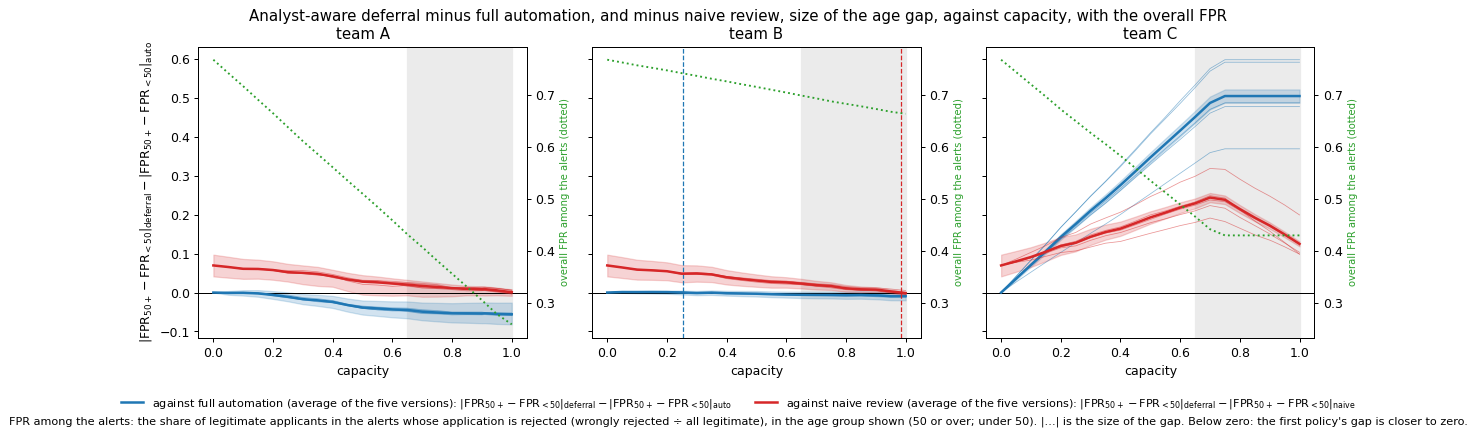

In [32]:
nb.section("P3-F3")

(1) As P2-F3, for analyst-aware deferral, against both other policies. Descriptive.

(2) Against full automation, analyst-aware deferral narrows the age gap with team A, shows no difference with team B, and widens it with team C at every realistic capacity. Against naive review, its gap is the larger with team C at every capacity, and with team B at every realistic capacity except the two highest; with team A it shows no difference in the realistic range. For team B at capacity 0.75, the deciding verdict, no difference shown, governs (section 3.2).

(3) On the age gap the first part is refuted (section 3.3).

<a id="a5-the-capacity-ranges-as-tables"></a>
### A.5 The capacity ranges, as tables

**Naive review: the capacity range over which it beats full automation, per team and measure, and the verdict at each capacity**

In [33]:
nb.section("P2-T4-tables")

,comparison,team,version,measure,where the difference crosses zero (capacity),summary (can be misread; see the caveat in the technical section),0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,10/11,0.95,1.00
15,against full automation,A,mean of 5 versions,"misclassification cost, difference","boundary at capacity 0.1496 (between 0.10 and 0.15; does worse below, better above)",never does worse; beats from capacity 0.45; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no ...,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅
16,against full automation,A,mean of 5 versions,"regulatory exposure (accepted frauds), difference","boundary at capacity 0.5005 (between 0.50 and 0.55; does better below, worse above)",beats up to capacity 0.30; does worse from capacity 0.70; between: 0.35: no difference shown; 0.40: no difference sh...,✅,✅,✅,✅,✅,✅,✅,🟡,🟡,🟡,🟡,🟡,🟡,🟡,❌,❌,❌,❌,❌,❌,❌,❌
17,against full automation,A,mean of 5 versions,"fairness exposure (absolute age gap), difference","no boundary in [0, 1]",never does worse; beats from capacity 0.00,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅
33,against full automation,B,mean of 5 versions,"misclassification cost, difference","boundary at capacity 0.5205 (between 0.50 and 0.55; does worse below, better above)",never does worse; beats from capacity 0.85; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no ...,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡*,🟡*,🟡*,🟡*,✅*,✅*,✅*,✅*,✅*
34,against full automation,B,mean of 5 versions,"regulatory exposure (accepted frauds), difference","boundary at capacity 0.8643 (between 0.85 and 0.90; does better below, worse above)",beats up to capacity 0.70; does worse from capacity 1.00; between: 0.75: no difference shown; 0.80: no difference sh...,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*,✅*,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,❌*
35,against full automation,B,mean of 5 versions,"fairness exposure (absolute age gap), difference","no boundary in [0, 1]",never does worse; does not beat at every capacity from any point up to 1; between: 0.00: beats; 0.05: beats; 0.10: b...,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*,🟡*
51,against full automation,C,mean of 5 versions,"misclassification cost, difference","boundary at capacity 0.1722 (between 0.15 and 0.20; does worse below, better above)",never does worse; beats from capacity 0.55; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no ...,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,✅,✅,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*
52,against full automation,C,mean of 5 versions,"regulatory exposure (accepted frauds), difference","boundary at capacity 0.6972 (between 0.65 and 0.70; does better below, worse above)",beats up to capacity 0.45; does worse from capacity 0.95; between: 0.50: no difference shown; 0.55: no difference sh...,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,🟡,🟡,🟡,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,❌*,❌*
53,against full automation,C,mean of 5 versions,"fairness exposure (absolute age gap), difference","boundary at capacity 0.1469 (between 0.10 and 0.15; does better below, worse above)",beats up to capacity 0.05; does worse from capacity 0.25; between: 0.10: no difference shown; 0.15: no difference sh...,✅,✅,🟡,🟡,🟡,❌,❌,❌,❌,❌,❌,❌,❌,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*


The rows of each single version are in the accompanying table file (54 rows in all).


**Analyst-aware deferral: the capacity range over which it beats full automation and naive review, per team and measure, and the verdict at each capacity**

In [34]:
nb.section("P3-T4-tables")

,comparison,team,version,measure,where the difference crosses zero (capacity),summary (can be misread; see the caveat in the technical section),0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,10/11,0.95,1.00
15,against full automation,A,mean of 5 versions,"misclassification cost, difference","no boundary in [0, 1] ; touches zero at capacity 0.00",never does worse; beats from capacity 0.05; between: 0.00: no difference shown,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*
16,against full automation,A,mean of 5 versions,"regulatory exposure (accepted frauds), difference","no boundary in [0, 1] ; touches zero at capacity 0.00",does worse up to capacity 1.00; never beats,🟡,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌*
17,against full automation,A,mean of 5 versions,"fairness exposure (absolute age gap), difference","no boundary in [0, 1] ; touches zero at capacity 0.00",never does worse; beats from capacity 0.30; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no ...,🟡,🟡,🟡,🟡,🟡,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*
33,against full automation,B,mean of 5 versions,"misclassification cost, difference","no boundary in [0, 1] ; touches zero at capacity 0.00",never does worse; beats from capacity 0.10; between: 0.00: no difference shown; 0.05: no difference shown,🟡,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*
34,against full automation,B,mean of 5 versions,"regulatory exposure (accepted frauds), difference","no boundary in [0, 1] ; touches zero at capacity 0.00",does worse up to capacity 1.00; never beats,🟡,❌,🟡,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*
35,against full automation,B,mean of 5 versions,"fairness exposure (absolute age gap), difference","touches zero at capacity 0.00 ; boundary at capacity 0.2538 (between 0.25 and 0.30; does worse below, better above)",never does worse; never beats; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no difference sh...,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*,🟡*
51,against full automation,C,mean of 5 versions,"misclassification cost, difference","no boundary in [0, 1] ; touches zero at capacity 0.00",never does worse; beats from capacity 0.05; between: 0.00: no difference shown,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*,✅*
52,against full automation,C,mean of 5 versions,"regulatory exposure (accepted frauds), difference","no boundary in [0, 1] ; touches zero at capacity 0.00",does worse up to capacity 1.00; never beats,🟡,🟡,🟡,🟡,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*
53,against full automation,C,mean of 5 versions,"fairness exposure (absolute age gap), difference","no boundary in [0, 1] ; touches zero at capacity 0.00",does worse up to capacity 1.00; never beats,🟡,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*,❌*
69,against naive review,A,mean of 5 versions,"misclassification cost, difference","no boundary in [0, 1]",never does worse; beats from capacity 0.20; between: 0.00: no difference shown; 0.05: no difference shown; 0.10: no ...,🟡,🟡,🟡,🟡,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅,✅*


The rows of each single version are in the accompanying table file (108 rows in all).


The crossings and verdicts in these tables are those described under each measure in section 4.2 and A.2 to A.4. On the average of the five versions, some descriptive verdicts at realistic capacities differ from the deciding verdicts of section 3; the list below is complete for the average only, and single versions differ in more places (the rows of each version are in the table files). Under naive review, against full automation: team B on misclassification cost at 0.85, 0.90 and 10/11, on frauds accepted at 0.65 and 0.70, and on the age gap at 0.70 to 0.95 (descriptive "beats", deciding "no difference shown"); team C on misclassification cost at 0.65 and 0.70 (descriptive "beats") and on frauds accepted at 0.95 and 1 (descriptive "does worse"), where the deciding verdict is "no difference shown". Under analyst-aware deferral: against full automation, on frauds accepted, team B at 0.65 to 0.95 and team C at 0.65 to 1 (descriptive "does worse", deciding "no difference shown"); against naive review, team B at 0.75 on misclassification cost (descriptive "beats") and on the age gap (descriptive "does worse"), where the deciding verdict is "no difference shown". In each case, and for every single version, the deciding verdict governs. Two readings are not supported: a crossing of zero is not a refutation on its own, and crossings at cost ratios other than 0.057 are not given here (section 4.9). The grid steps by 0.05, so a crossing is located only to within that step. A summary that reads "does worse up to capacity X; never beats" can be misread; the caveat in the technical section explains it.

<a id="a6-team-cs-bias-the-tables"></a>
### A.6 Team C's bias: the tables

**Naive review: how team C's bias changes between capacity 0.75 and full capacity**

In [35]:
nb.section("P2-F5-table")

,team,version,capacities compared,measure,change (point figure),"95% range, low","95% range, high",verdict,reading,kind
0,C,1,0.75 vs 1.00,fairness exposure (signed age gap),-0.095546,-0.104526,-0.086712,✅,cancels (in part),"check, by construction"
1,C,2,0.75 vs 1.00,fairness exposure (signed age gap),-0.109869,-0.118886,-0.100867,✅,cancels (in part),"check, by construction"
2,C,3,0.75 vs 1.00,fairness exposure (signed age gap),-0.125764,-0.135752,-0.115917,✅,cancels (in part),"check, by construction"
3,C,4,0.75 vs 1.00,fairness exposure (signed age gap),-0.078428,-0.086736,-0.070270,✅,cancels (in part),"check, by construction"
4,C,5,0.75 vs 1.00,fairness exposure (signed age gap),-0.103057,-0.112389,-0.093888,✅,cancels (in part),"check, by construction"
5,C,mean of 5 versions,0.75 vs 1.00,fairness exposure (signed age gap),-0.102533,-0.110865,-0.094350,✅,cancels (in part),"check, by construction"
6,C,1,0.75 vs 1.00,FP among applicants aged 50 or over (count),-109.400000,-121.000000,-98.000000,✅,cancels (in part),"check, by construction"
7,C,2,0.75 vs 1.00,FP among applicants aged 50 or over (count),-125.800000,-138.000000,-113.800000,✅,cancels (in part),"check, by construction"
8,C,3,0.75 vs 1.00,FP among applicants aged 50 or over (count),-144.000000,-157.405000,-130.800000,✅,cancels (in part),"check, by construction"
9,C,4,0.75 vs 1.00,FP among applicants aged 50 or over (count),-89.800000,-100.400000,-79.400000,✅,cancels (in part),"check, by construction"


*FPR among the alerts.*

**Analyst-aware deferral: how the difference between teams C and A changes between capacity 0.75 and full capacity**

The table gives the same measure for analyst-aware deferral, but there it measures something else. Team C's routing is the same at 0.75 and at full capacity, so the measure reduces to team A's own change between the two capacities and says nothing about team C's bias, although the rows are labelled team C. Its readings ("cancels (in part)", "additive"), the kind "finding" and its verdicts describe team A's change only.

In [36]:
nb.section("P3-T7")

,team,version,capacities compared,measure,change (point figure),"95% range, low","95% range, high",verdict,reading,kind
0,C,1,0.75 vs 1.00,fairness exposure (signed age gap),-0.008572,-0.020475,0.003334,🟡,additive,finding
1,C,2,0.75 vs 1.00,fairness exposure (signed age gap),-0.003820,-0.016487,0.008917,🟡,additive,finding
2,C,3,0.75 vs 1.00,fairness exposure (signed age gap),-0.006035,-0.018671,0.006644,🟡,additive,finding
3,C,4,0.75 vs 1.00,fairness exposure (signed age gap),-0.000554,-0.011968,0.010686,🟡,additive,finding
4,C,5,0.75 vs 1.00,fairness exposure (signed age gap),-0.003940,-0.016101,0.008283,🟡,additive,finding
5,C,mean of 5 versions,0.75 vs 1.00,fairness exposure (signed age gap),-0.004584,-0.015556,0.006457,🟡,additive,finding
6,C,1,0.75 vs 1.00,FP among applicants aged 50 or over (count),-143.200000,-156.600000,-130.000000,✅,cancels (in part),finding
7,C,2,0.75 vs 1.00,FP among applicants aged 50 or over (count),-172.800000,-187.800000,-158.200000,✅,cancels (in part),finding
8,C,3,0.75 vs 1.00,FP among applicants aged 50 or over (count),-173.400000,-188.400000,-158.600000,✅,cancels (in part),finding
9,C,4,0.75 vs 1.00,FP among applicants aged 50 or over (count),-94.400000,-106.200000,-82.800000,✅,cancels (in part),finding


*FPR among the alerts.*

- **Naive review.** Team C's excess over team A, on the signed age gap and on the number of wrongly rejected applicants aged 50 or over, is smaller at capacity 0.75 than at full capacity, in all five versions. This direction follows from the rules and is a check, not a finding: team C's age-gap difference from full automation grows with capacity, and team C does worse on the age gap even at full capacity, where nothing is beyond capacity. The one finding is on misclassification cost: its verdict is "beats" and its reading "cancels (in part)"; three of the five versions read "cancels (in part)" and two "additive". The line expected if the bias scaled with capacity supports no verdict.
- **Analyst-aware deferral.** Team C's routing is the same at capacity 0.75 and at full capacity. The measure therefore reduces to team A's own change between the two capacities: it says nothing about team C's bias, and its readings describe team A only. On the signed age gap, no difference is shown and the reading is "additive"; on the number of wrongly rejected applicants aged 50 or over and on misclassification cost, the verdict is "beats" and the reading "cancels (in part)", in all five versions.

Neither result shows that overload degrades reviewers' judgement or that a bias in real reviewers acts this way.

<a id="a7-access-by-age-group-the-tables"></a>
### A.7 Access by age group: the tables

**Share of alerts sent to a reviewer, by age group, analyst-aware deferral beside naive review**

This table and graph ask who gets access to a human reviewer. The alerts fall into four groups: applicants aged 50 or over or under 50, and alerts the classifier would confirm (rejecting the application) or would dismiss. For each group, the share of alerts sent to a reviewer is shown (i) overall, (ii) among the alerts the classifier would confirm, and (iii) among those it would dismiss, with the difference between the age groups in percentage points. Analyst-aware deferral is shown beside naive review at the same capacity. The figures are point figures, pooled over the five versions and five random orders, without a range or a verdict. Some cells follow directly from the rules and are labelled "by construction".

In [37]:
nb.section("P3-T9")

analyst-aware deferral, team C, applicants aged 50 or over whose alert the classifier would confirm: sent to a reviewer in 0 of 24 rows (0 by construction)
analyst-aware deferral, team B equal to team A in every figure: True


**Team A, average of the five versions**

,capacity,share kind,policy,"share, 50 or over","share, under 50",difference (percentage points),"counts, 50 or over (sent / alerts x routings)","counts, under 50 (sent / alerts x routings)",note
30,1.00,(i) overall,naive review,1.0000,1.0000,+0.00,"35,425 / (1,417 x 25)","76,000 / (3,040 x 25)",
31,1.00,(i) overall,analyst-aware deferral,0.9816,0.9895,-0.79,"34,773 / (1,417 x 25)","75,199 / (3,040 x 25)",
32,1.00,(ii) classifier would confirm,naive review,1.0000,1.0000,+0.00,"29,875 / (1,195 x 25)","58,850 / (2,354 x 25)",
33,1.00,(ii) classifier would confirm,analyst-aware deferral,0.9784,0.9866,-0.81,"29,230 / (1,195 x 25)","58,059 / (2,354 x 25)",
34,1.00,(iii) classifier would dismiss,naive review,1.0000,1.0000,+0.00,"5,550 / (222 x 25)","17,150 / (686 x 25)",
35,1.00,(iii) classifier would dismiss,analyst-aware deferral,0.9987,0.9994,-0.07,"5,543 / (222 x 25)","17,140 / (686 x 25)",
66,10/11,(i) overall,naive review,0.9132,0.9069,+0.63,"32,350 / (1,417 x 25)","68,925 / (3,040 x 25)",
67,10/11,(i) overall,analyst-aware deferral,0.9077,0.9095,-0.18,"32,154 / (1,417 x 25)","69,121 / (3,040 x 25)",
68,10/11,(ii) classifier would confirm,naive review,0.9130,0.9064,+0.66,"27,275 / (1,195 x 25)","53,340 / (2,354 x 25)",
69,10/11,(ii) classifier would confirm,analyst-aware deferral,0.9040,0.9069,-0.29,"27,007 / (1,195 x 25)","53,373 / (2,354 x 25)",


**Team B, average of the five versions** — identical to team A by construction

,capacity,share kind,policy,"share, 50 or over","share, under 50",difference (percentage points),"counts, 50 or over (sent / alerts x routings)","counts, under 50 (sent / alerts x routings)",note
174,1.00,(i) overall,naive review,1.0000,1.0000,+0.00,"35,425 / (1,417 x 25)","76,000 / (3,040 x 25)",
175,1.00,(i) overall,analyst-aware deferral,0.9816,0.9895,-0.79,"34,773 / (1,417 x 25)","75,199 / (3,040 x 25)",identical to team A by construction
176,1.00,(ii) classifier would confirm,naive review,1.0000,1.0000,+0.00,"29,875 / (1,195 x 25)","58,850 / (2,354 x 25)",
177,1.00,(ii) classifier would confirm,analyst-aware deferral,0.9784,0.9866,-0.81,"29,230 / (1,195 x 25)","58,059 / (2,354 x 25)",identical to team A by construction
178,1.00,(iii) classifier would dismiss,naive review,1.0000,1.0000,+0.00,"5,550 / (222 x 25)","17,150 / (686 x 25)",
179,1.00,(iii) classifier would dismiss,analyst-aware deferral,0.9987,0.9994,-0.07,"5,543 / (222 x 25)","17,140 / (686 x 25)",identical to team A by construction
210,10/11,(i) overall,naive review,0.9132,0.9069,+0.63,"32,350 / (1,417 x 25)","68,925 / (3,040 x 25)",
211,10/11,(i) overall,analyst-aware deferral,0.9077,0.9095,-0.18,"32,154 / (1,417 x 25)","69,121 / (3,040 x 25)",identical to team A by construction
212,10/11,(ii) classifier would confirm,naive review,0.9130,0.9064,+0.66,"27,275 / (1,195 x 25)","53,340 / (2,354 x 25)",
213,10/11,(ii) classifier would confirm,analyst-aware deferral,0.9040,0.9069,-0.29,"27,007 / (1,195 x 25)","53,373 / (2,354 x 25)",identical to team A by construction


**Team C, average of the five versions**

,capacity,share kind,policy,"share, 50 or over","share, under 50",difference (percentage points),"counts, 50 or over (sent / alerts x routings)","counts, under 50 (sent / alerts x routings)",note
318,1.00,(i) overall,naive review,1.0000,1.0000,+0.00,"35,425 / (1,417 x 25)","76,000 / (3,040 x 25)",note: Policy 2's overall share for applicants aged 50 or over includes these alerts.
319,1.00,(i) overall,analyst-aware deferral,0.1565,0.9895,-83.30,"5,543 / (1,417 x 25)","75,199 / (3,040 x 25)",—
320,1.00,(ii) classifier would confirm,naive review,1.0000,1.0000,+0.00,"29,875 / (1,195 x 25)","58,850 / (2,354 x 25)","[50 or over]: Reviewed, but the outcome is fixed by team C's rule: every such alert is confirmed under policies 1, 2..."
321,1.00,(ii) classifier would confirm,analyst-aware deferral,0.0000,0.9866,-98.66,"0 / (1,195 x 25)","58,059 / (2,354 x 25)",[50 or over]: 0 by construction
322,1.00,(iii) classifier would dismiss,naive review,1.0000,1.0000,+0.00,"5,550 / (222 x 25)","17,150 / (686 x 25)",—
323,1.00,(iii) classifier would dismiss,analyst-aware deferral,0.9987,0.9994,-0.07,"5,543 / (222 x 25)","17,140 / (686 x 25)",—
354,10/11,(i) overall,naive review,0.9132,0.9069,+0.63,"32,350 / (1,417 x 25)","68,925 / (3,040 x 25)",note: Policy 2's overall share for applicants aged 50 or over includes these alerts.
355,10/11,(i) overall,analyst-aware deferral,0.1565,0.9895,-83.30,"5,543 / (1,417 x 25)","75,199 / (3,040 x 25)",—
356,10/11,(ii) classifier would confirm,naive review,0.9130,0.9064,+0.66,"27,275 / (1,195 x 25)","53,340 / (2,354 x 25)","[50 or over]: Reviewed, but the outcome is fixed by team C's rule: every such alert is confirmed under policies 1, 2..."
357,10/11,(ii) classifier would confirm,analyst-aware deferral,0.0000,0.9866,-98.66,"0 / (1,195 x 25)","58,059 / (2,354 x 25)",[50 or over]: 0 by construction


**One version, with the range over the five random orders** (every team and version is in the accompanying table file). Example: team C, version 1.

,capacity,share kind,policy,"share, 50 or over","share, under 50",difference (percentage points),"counts, 50 or over (sent / alerts x routings)","counts, under 50 (sent / alerts x routings)","range over the five random orders, 50 or over","range over the five random orders, under 50",note
288,1.00,(i) overall,naive review,1.0000,1.0000,+0.00,"7,085 / (1,417 x 5)","15,200 / (3,040 x 5)",1.0000 to 1.0000,1.0000 to 1.0000,note: Policy 2's overall share for applicants aged 50 or over includes these alerts.
289,1.00,(i) overall,analyst-aware deferral,0.1564,0.9886,-83.22,"1,108 / (1,417 x 5)","15,026 / (3,040 x 5)",0.1560 to 0.1567,0.9872 to 0.9895,—
290,1.00,(ii) classifier would confirm,naive review,1.0000,1.0000,+0.00,"5,975 / (1,195 x 5)","11,770 / (2,354 x 5)",1.0000 to 1.0000,1.0000 to 1.0000,"[50 or over]: Reviewed, but the outcome is fixed by team C's rule: every such alert is confirmed under policies 1, 2..."
291,1.00,(ii) classifier would confirm,analyst-aware deferral,0.0000,0.9854,-98.54,"0 / (1,195 x 5)","11,598 / (2,354 x 5)",0.0000 to 0.0000,0.9834 to 0.9864,[50 or over]: 0 by construction
292,1.00,(iii) classifier would dismiss,naive review,1.0000,1.0000,+0.00,"1,110 / (222 x 5)","3,430 / (686 x 5)",1.0000 to 1.0000,1.0000 to 1.0000,—
293,1.00,(iii) classifier would dismiss,analyst-aware deferral,0.9982,0.9994,-0.12,"1,108 / (222 x 5)","3,428 / (686 x 5)",0.9955 to 1.0000,0.9971 to 1.0000,—
324,10/11,(i) overall,naive review,0.9132,0.9069,+0.63,"6,470 / (1,417 x 5)","13,785 / (3,040 x 5)",0.9026 to 0.9224,0.9026 to 0.9118,note: Policy 2's overall share for applicants aged 50 or over includes these alerts.
325,10/11,(i) overall,analyst-aware deferral,0.1564,0.9886,-83.22,"1,108 / (1,417 x 5)","15,026 / (3,040 x 5)",0.1560 to 0.1567,0.9872 to 0.9895,—
326,10/11,(ii) classifier would confirm,naive review,0.9130,0.9064,+0.66,"5,455 / (1,195 x 5)","10,668 / (2,354 x 5)",0.9046 to 0.9238,0.8985 to 0.9133,"[50 or over]: Reviewed, but the outcome is fixed by team C's rule: every such alert is confirmed under policies 1, 2..."
327,10/11,(ii) classifier would confirm,analyst-aware deferral,0.0000,0.9854,-98.54,"0 / (1,195 x 5)","11,598 / (2,354 x 5)",0.0000 to 0.0000,0.9834 to 0.9864,[50 or over]: 0 by construction


<a id="a8-other-cost-ratios-the-tables-and-the-comparison-with-confirm-every-alert"></a>
### A.8 Other cost ratios: the tables and the comparison with "confirm every alert"

The table labels each team and capacity: **"conditional"** if it beats full automation at one or more of the other cost ratios and does worse at none; **"not robust"** if it beats at one or more and does worse at one or more. An empty label means the team beats full automation at none of the other cost ratios; it does not mean "no difference".

In [38]:
nb.section("P2-F7-tables")

,team,version,capacity,beats full automation at cost ratios,does worse at cost ratios,verdict at 0.035,verdict at 0.0537,verdict at 0.057,verdict at 0.171,where the break-even lies,qualifier,across cost ratios
119,A,mean of 5 versions,0.45,0.171,—,🟡,🟡,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035); 0.0537...",against an automation baseline not re-optimised for this cost ratio,conditional
120,A,mean of 5 versions,0.50,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
121,A,mean of 5 versions,0.55,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
122,A,mean of 5 versions,0.60,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
123,A,mean of 5 versions,0.65,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
124,A,mean of 5 versions,0.70,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
125,A,mean of 5 versions,0.75,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
126,A,mean of 5 versions,0.80,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
127,A,mean of 5 versions,0.85,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional
128,A,mean of 5 versions,0.90,"0.0537, 0.171",—,🟡,✅,✅,✅,"0.035: the break-even lies between 0.057 and the tested ratio (beats at 0.057, no difference shown at 0.035)",against an automation baseline not re-optimised for this cost ratio,conditional


Naive review: how each team's result holds across cost ratios (average of the five versions; rows: team; columns: capacity; empty: the team beats full automation at none of the other cost ratios)


capacity,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,10/11,0.95,1.00
team,,,,,,,,,,,,,,,,,,,,,,
A,,,,,,,,,,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional
B,,,,,,,,,,,,,,,,,conditional,conditional,conditional,conditional,conditional,conditional
C,,,,not robust,not robust,not robust,,,conditional,,,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional


In [39]:
nb.section("P3-F6-tables")

Analyst-aware deferral: how each team's result holds across cost ratios (average of the five versions; rows: team; columns: capacity; empty: the team beats full automation at none of the other cost ratios)


capacity,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,10/11,0.95,1.00
team,,,,,,,,,,,,,,,,,,,,,,
A,,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional
B,,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional
C,,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional,conditional


**Against "confirm every alert" at cost ratio 0.035: the results quoted below**

At cost ratio 0.035, confirming every alert has a lower misclassification cost than full automation in point value (section A.1), so beating full automation there does not mean beating the cheaper automated option. The graph gives naive review's comparison with confirming every alert for team C at capacity 0.15, and analyst-aware deferral's for teams A, B and C at capacities 0.75 and 1. Each marker is the misclassification-cost difference, the policy minus confirming every alert, averaged over the five versions, with its 95% range and its verdict. These results are descriptive and decide nothing. They are read from the run's full results by their key columns, with nothing recomputed.

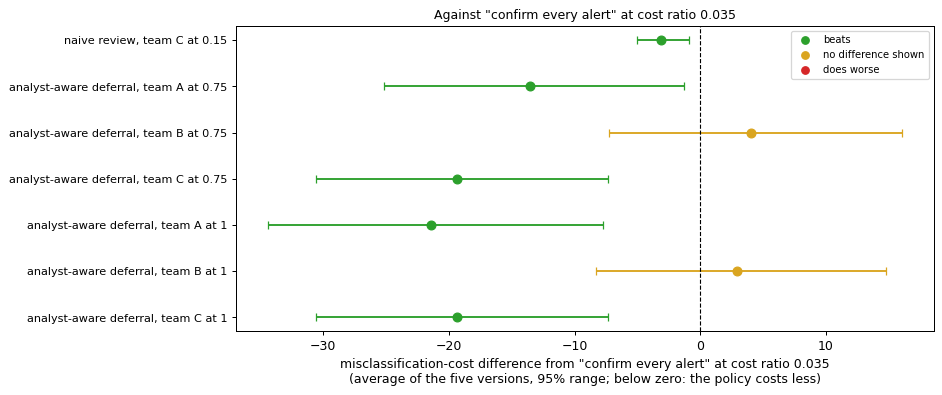

In [40]:
nb.section("rows-0035")

- **Naive review.** Team A is labelled "conditional" from capacity 0.45 to 1 and team B from 0.80 to 1; team C is labelled "not robust" at 0.15 to 0.25 and "conditional" at 0.40 and from 0.55 to 1. The rows left empty are team A at 0 to 0.40, team B at 0 to 0.75, and team C at 0 to 0.10, 0.30, 0.35, 0.45 and 0.50; the team does worse at 0.171 in 7 of team A's 9 empty rows, 14 of team B's 16 and 5 of team C's 7. At 0.171, each team does worse at low capacities where it shows no difference at 0.057: team A at 0 to 0.30, team B at 0 to 0.65 and team C at 0 to 0.35. At 0.035, most results that beat at 0.057 show no difference: all of team A's and team B's, and 4 of team C's 11 (0.55 to 0.70); team C still beats at 0.75 to 1. Where a verdict changes, the break-even lies between 0.057 and the tested ratio.
- **At 0.035**, confirming every alert has the lower misclassification cost of the two automated options in point value (section A.1; a reference, not a finding). Under naive review, only team C beats full automation at 0.035, at capacities 0.15 to 0.25, 0.40 and 0.75 to 1; at the capacity shown in the graph above, it also beats confirming every alert.
- **Analyst-aware deferral.** Every team is labelled "conditional" at every capacity above 0; no result is "not robust". At 0.035, team A beats full automation at every capacity from 0.05 but does not also beat confirming every alert at 14 of them (0.05 to 0.70); team B beats full automation at 14 capacities (0.40 to 1) and confirming every alert at none of them; team C beats full automation at every capacity from 0.05 but does not also beat confirming every alert at 10 of them (0.05 to 0.50). At the two capacities shown in the graph above, teams A and C also beat confirming every alert; team B does not.

Away from 0.057, neither full automation, the reviewers nor the router is re-tuned for the cost ratio, so no result here shows a team beating full automation robustly across cost ratios. The graph just above gives the results against confirming every alert, with their ranges and verdicts.

<a id="a9-predictions-from-the-rules"></a>
### A.9 Predictions from the rules

Several outcomes were predicted from the rules. All are reported, whether they held or not:
- **Team B moves only about a fifth of the way from full automation**, because it takes the model's decision on most alerts where the reviewer disagrees. Held: at full capacity, team B's difference from full automation is 0.20 of team A's on misclassification cost and 0.21 on frauds accepted.
- **Under naive review, the alerts beyond capacity raise misclassification cost at every realistic capacity below full.** Held in point value at the realistic capacities except 0.95; the alerts beyond capacity are not shown to change misclassification cost in either direction.
- **Team B against team A at 0.75 takes the opposite direction to team A against full automation.** Held on misclassification cost and on frauds accepted: team B does worse than team A on misclassification cost and beats it on frauds accepted, the opposite of team A against full automation; on the age gap, no difference is shown. This is a consistency reading, not a check, because team A's comparison is at full capacity.
- **Team C accepts no more frauds than team A, and its signed age gap is at least team A's**, in every random order and version. Held in every random order of every version at all 22 capacities (110 of 110 version and capacity rows).
- **On the alerts naive review confirms without review**, analyst-aware deferral accepts as many frauds or more and has the lower misclassification cost. Held for teams B and C: it accepts more frauds on these alerts and, averaged over the random orders, has the lower misclassification cost in every version (`tables/P3-T8_point_figures.csv`).
- **Under analyst-aware deferral, team C sends no alert of an applicant aged 50 or over that the classifier would confirm to a reviewer, and team B's access figures equal team A's.** Held in every version, random order and capacity (section 4.5).

<a id="a10-the-full-sweep"></a>
### A.10 The full sweep

**Naive review: every team and capacity (average of the five versions; versions and other cost ratios in the table files)**

The project outline requires the full sweep to be reported, including settings in which naive review performs acceptably. These tables show the differences from full automation (and, for analyst-aware deferral, from naive review) for every team and capacity, with the 95% range, the descriptive verdict and the range over the five random orders. In these tables, "seeds" means the five random orders. Every team version, cost ratio and further measure is in the full table files that accompany the notebook.

In [41]:
nb.section("P2-T5")

*FPR among the alerts.*

**Analyst-aware deferral: every team and capacity (average of the five versions; versions and other cost ratios in the table files)**

In [42]:
nb.section("P3-T5")

*FPR among the alerts.*

Nothing in the sweep is left out: every team, version, capacity, cost ratio and measure that was run is in these tables or in their table files, and every row not discussed above is descriptive and decides nothing. These tables hold the differences from full automation and, for analyst-aware deferral, from naive review. Full automation's own figures (section A.1), the deciding results with their widened ranges (sections 3.1 and 3.2, and in full in the technical section), the figures on the alerts naive review confirms without review (`tables/P3-T8_point_figures.csv`) and the shares of alerts sent to a reviewer (section A.7) are in their own tables.

<a id="a11-differences-expected-by-chance"></a>
### A.11 Differences expected by chance

**Naive review: observed "beats" and "does worse" against the number expected by chance**

With so many descriptive comparisons, some would show a difference by chance alone. Each graph sets the number of descriptive "beats" and "does worse" verdicts against full automation against the number expected by chance (2.5% on each side). Neighbouring capacities are not independent, so this is a guide, not a test.

The two results fixed by construction compare two teams, so none is in the counted set; this exclusion removes nothing.

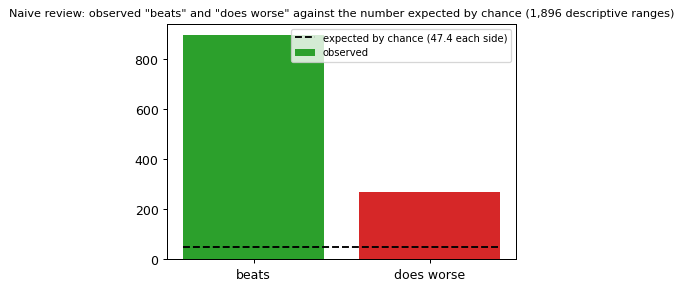

,descriptive ranges counted,beats,does worse,expected by chance on each side,results counted,note
0,1896,898,271,47.4,"each of the 15 team instances against policy 1, at every grid capacity above 0; misclassification cost at 4 cost rat...","the expected number assumes independent intervals; a guide, not a test"


In [43]:
nb.section("P2-F8")

(1) With many descriptive ranges, some differ from zero by chance alone. The graph compares the observed count with that number, so that the descriptive results are not over-read. Descriptive.

(2) Both "beats" and "does worse" occur far more often than the number expected by chance.

(3) The comparison is a guide to reading, not a test: the descriptive ranges share the same re-draws and overlap across capacities, versions and the average of the five, so the number expected by chance does not say how rare the observed counts would be. Each single descriptive result decides nothing.

**Analyst-aware deferral: observed "beats" and "does worse" against the number expected by chance**

Capacity 0 is left out entirely, because there analyst-aware deferral is full automation.

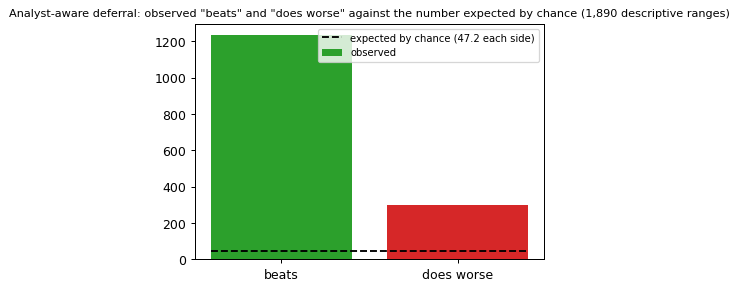

,descriptive ranges counted,beats,does worse,expected by chance on each side,results counted,note
0,1890,1235,301,47.25,"each of the 15 team instances against policy 1, at every grid capacity above 0; misclassification cost at 4 cost rat...","the expected number assumes independent intervals; a guide, not a test"


In [44]:
nb.section("P3-F7")

(1) As P2-F8, for analyst-aware deferral. Descriptive.

(2) As for naive review, both counts are far above the number expected by chance.

(3) As for P2-F8: a guide to reading, not a test.

# Technical section

This section is not needed to read the results. It holds the state of the switch in this run, the input checksums and their outcome, the map from each item above to the study design's identifiers and to the files the run writes, the label texts, the full deciding tables with a graph of each result and its range, and the caveat on the boundary summaries. It ends with the run time and peak memory of every step of this run, and with the cell that collects the run's outputs in one archive. The study design's identifiers appear here.

<a id="the-switch-in-this-run"></a>
## The switch in this run

In [45]:
nb.switch_state()

HYPERPARAM_TUNE = False in this run: the router's 250 models were refitted from the settings the study's search chose.


<a id="input-checksums"></a>
## Input checksums

In [46]:
nb.input_checksums()

inputs,files listed in results/input_checksums.csv,outcome
FiFAR files (figshare),132,each equal to its listed sha256
"framework files (OpenL2D at cfe5fd0, after the patches)",10,each equal to its listed sha256


<a id="map-from-each-item-to-its-design-identifier"></a>
## Map from each item to its design identifier

Each row names an item of the notebook, the identifier of the table or graph in the study's design that it shows, and the files this run writes for it, in its folders `tables/` and `figures/`. The two grids P2-F10 and P3-F10 draw the deciding results of P2-T3 and P3-T3; rows-split and rows-0035 are rows of the full sweep tables P3-T5 and P2-T5, read by their key columns. The files in `tables/` keep the study's internal column names: columns named with "expected_loss" hold the misclassification cost, and columns named with "false_rejection_rate" hold the FPR (likewise "false_rejections" holds the FP count and "miss_rate" the FNR).

| Order | Section | Item | Design identifier | Files the run writes |
|---|---|---|---|---|
| 0a | 2 | Which months the study uses, and for what | F-months (new) | `figures/F-months_months_used.png` |
| 0b | 2 | What the applications show: label, age and features (panels D1 to D5) | F-data (new) | `figures/F-data_applications.png` |
| 1 | 3.1 | Naive review: the results that decide, in one grid | P2-F10 (from P2-T3) | `figures/P2-F10_deciding_results.png`; `tables/P2-T3_deciding_results.csv`, `tables/P2-T3b_realistic_range_verdicts.csv`, `tables/P2-T3c_rule_outcomes.csv` |
| 2 | 3.2 | Analyst-aware deferral: the results that decide, in one grid; FPR and FNR of each age group at 0.75 (new) | P3-F10 (from P3-T3); P3-F11 (new) | `figures/P3-F10_deciding_results.png`; `tables/P3-T3_deciding_results.csv`, `tables/P3-T3b_realistic_range_verdicts.csv`, `tables/P3-T3c_rule_outcomes.csv`; `figures/P3-F11_fpr_fnr_by_age.png` |
| 3 | A.2 (long notebook) | Analyst-aware deferral minus naive review, misclassification cost, split into the alerts left to the classifier and the alerts reviewed | P3-F4 | `figures/P3-F4_split.png` |
| 4 | — | Teams B and C at capacity 0.75: the difference on the alerts naive review confirms without review (file only; no longer shown) | P3-T8 | `tables/P3-T8_point_figures.csv` |
| 5 | 4.7 | Analyst-aware deferral minus naive review, split into the alerts left to the classifier and the alerts reviewed, on both measures, with ranges and verdicts | rows of P3-T5, as a range graph | `tables/rows-split.csv`, `figures/rows-split_parts_range.png` |
| 6 | 4.8 | Analyst-aware deferral: how many alerts went to a reviewer, to which reviewer, and to the classifier | P3-T1 (routing), as two graphs | `tables/P3-T1a_routing.csv`, `figures/P3-T1_allocation.png`, `figures/P3-T1_reviewer_shares.png` |
| 7 | 4.8 | How well the router tells apart the alerts each reviewer gets right from those the reviewer gets wrong | P3-T1 (ranking quality) | `tables/P3-T1b_ranking_quality_per_model_month6.csv`, `tables/P3-T1b_ranking_quality_per_model_month7.csv`, `tables/P3-T1c_ranking_quality_by_version.csv`, `figures/P3-T1r_ranking_quality.png` |
| 8 | 4.4 | The 50 reviewers against Classifier h on the test month, in ROC space (the P2-T1 tables as files only) | P2-T1 | `tables/P2-T1a_members_slot_order.csv`, `tables/P2-T1c_team_version_rates.csv`, `tables/P2-T1d_twins.csv`, `tables/P2-T1e_month7_items.csv`, `figures/P2-T1_reviewers_roc.png` |
| 9 | A.1 (long notebook) | Full automation and "confirm every alert": the three measures at each cost ratio | P1-T2 | `tables/P1-T2_baseline_by_cost_ratio.csv` |
| 10 | A.1 (long notebook) | Full automation and "confirm every alert": the three measures against the cost ratio | P1-F1 | `figures/P1-F1_measures_vs_cost_ratio.png` |
| 11 | A.2 (long notebook) | Naive review minus full automation, misclassification cost, against capacity | P2-F1 | `figures/P2-F1_expected_loss.png` |
| 12 | 4.2 | Analyst-aware deferral minus full automation, and minus naive review, misclassification cost, against capacity | P3-F1 | `figures/P3-F1_expected_loss.png` |
| 13 | A.2 (long notebook) | Naive review minus full automation, misclassification cost, split into the reviewed alerts and the alerts beyond capacity | P2-F4 | `figures/P2-F4_split.png` |
| 14 | A.3 (long notebook) | Naive review minus full automation, frauds accepted, against capacity | P2-F2 | `figures/P2-F2_accepted_frauds.png` |
| 15 | A.3 (long notebook) | Analyst-aware deferral minus full automation, and minus naive review, frauds accepted, against capacity | P3-F2 | `figures/P3-F2_accepted_frauds.png` |
| 16 | A.4 (long notebook) | Naive review minus full automation, size of the age gap, against capacity, with the overall FPR | P2-F3 | `figures/P2-F3_absolute_age_gap.png` |
| 17 | A.4 (long notebook) | Analyst-aware deferral minus full automation, and minus naive review, size of the age gap, against capacity, with the overall FPR | P3-F3 | `figures/P3-F3_absolute_age_gap.png` |
| 17a | 4.5 | FPRs on every application of the test month, descriptive | P3-T10 (new) | — (shown only) |
| 18 | 4.1; table A.5 (long notebook) | Naive review: the capacity range over which it beats full automation, per team and measure, and the verdict at each capacity | P2-T4, with its colour grid | `tables/P2-T4_capacity_boundaries.csv`, `figures/P2-T4_verdict_grid.png` |
| 19 | 4.1; table A.5 (long notebook) | Analyst-aware deferral against full automation: the descriptive verdict at each capacity; analyst-aware deferral against naive review: the descriptive verdict at each capacity | P3-T4, with its colour grid | `tables/P3-T4_capacity_boundaries.csv`, `figures/P3-T4_verdict_grid_against_full_automation.png`, `figures/P3-T4_verdict_grid_against_naive_review.png` |
| 20 | 4.6; table A.6 (long notebook) | Naive review: FPRs by age group for teams C and A against capacity, and how team C's bias changes between capacity 0.75 and full capacity | P2-F5 | `figures/P2-F5_bias_x_capacity.png`, `tables/P2-F5_bias_x_capacity_I.csv` |
| 21 | A.6 (long notebook) | Analyst-aware deferral: how the difference between teams C and A changes between capacity 0.75 and full capacity | P3-T7 | `tables/P3-T7_bias_x_capacity.csv` |
| 22 | A.7 (long notebook) | Share of alerts sent to a reviewer, by age group, analyst-aware deferral beside naive review | P3-T9 | `tables/P3-T9_access_by_age.csv` |
| 23 | 4.5 | Team C: share of alerts sent to a reviewer against capacity, by age group, analyst-aware deferral and naive review | P3-F9 | `figures/P3-F9_access_by_age.png`, `tables/P3-F9_lines.csv` |
| 24 | 4.9; tables A.8 (long notebook) | Naive review: misclassification-cost verdict against full automation at each cost ratio and capacity; how each team's result holds across cost ratios | P2-F7 | `figures/P2-F7_cost_ratio_grid.png`, `tables/P2-F7_cost_ratio_labels.csv` |
| 25 | 4.9; table A.8 (long notebook) | Analyst-aware deferral: misclassification-cost verdict against full automation at each cost ratio and capacity; how each team's result holds across cost ratios | P3-F6 | `figures/P3-F6_cost_ratio_grid.png`, `tables/P3-F6_cost_ratio_labels.csv` |
| 26 | A.8 (long notebook) | Naive review and analyst-aware deferral against "confirm every alert", misclassification cost at cost ratio 0.035 | rows of P2-T5 and P3-T5, as a range graph | `tables/rows-0035.csv`, `figures/rows-0035_range.png` |
| 27 | 4.3 | Naive review: monitoring indicators against capacity, per team | P2-F6 | `figures/P2-F6_monitoring.png` |
| 28 | 4.3 | Analyst-aware deferral: monitoring indicators against capacity, per team, with criterion 1 as it turns out | P3-F5 | `figures/P3-F5_monitoring.png` |
| 29 | A.10 (long notebook) | Naive review: every team, version, capacity and cost ratio, all measures | P2-T5 | `tables/P2-T5_full_sweep.csv` |
| 30 | A.10 (long notebook) | Analyst-aware deferral: every team, version, capacity and cost ratio, all measures | P3-T5 | `tables/P3-T5_full_sweep.csv` |
| 31 | A.11 (long notebook) | Naive review: observed "beats" and "does worse" against the number expected by chance | P2-F8 | `figures/P2-F8_chance_count.png` |
| 32 | A.11 (long notebook) | Analyst-aware deferral: observed "beats" and "does worse" against the number expected by chance | P3-F7 | `figures/P3-F7_chance_count.png` |
| 33 | technical | Naive review: the results that decide, in full, with their widened ranges | P2-T3, P2-F9 | the three P2-T3 files of row 1; `figures/P2-F9_forest.png` |
| 34 | technical | Analyst-aware deferral: the results that decide, in full, with their widened ranges | P3-T3, P3-F8 | the three P3-T3 files of row 2; `figures/P3-F8_forest.png` |
| 35 | technical | Run time and memory of this run | T-T1 (this run's own records) | — (no file of its own; the table is formed from the run's `logs/steps.jsonl`, which the archive holds) |

<a id="label-texts"></a>
## Label texts

The texts of the labels the tables carry, as the study's design sets them. Sentences that refer to the study's own checks and run records, and references to its internal decision numbers, are left out; nothing else is changed.

In [47]:
nb.section("T-labels")

**L_P1**, used by: P1-T2

```text
95% case-bootstrap interval, B = 1,000 (rows 0 to 999 of the shared index matrix).
```

**L_P2_DEC**, used by: P2-T3

```text
Deciding result, one of 61. Interval adjusted for 61 results (1 − 0.05/61, about 99.918%; ends at the 0.0410th and 99.9590th percentiles), B = 50,000. Verdict by the five-version rule.
```

**L_P2K**, used by: P2-T3

```text
Fixed by construction (P2-K); not a finding.
```

**L_P3_DEC**, used by: P3-T3

```text
Deciding result, one of 66. Interval adjusted for 66 results (1 − 0.05/66, about 99.924%; ends at the 0.0379th and 99.9621st percentiles), B = 50,000. Verdict by the five-version rule. Adjusted among policy 3's 66 only, not together with policy 2's 61.
```

**L_DESC**, used by: P2-T4, P2-T5, P2-F5, P2-F7, P3-T4, P3-T5, P3-F6, P3-T7

```text
Descriptive: 95% interval, B = 50,000; verdict from the mean of the five versions at 95%. Not a deciding result; may differ from a deciding verdict on the same measure.
```

**L_RULE**, used by: P2-T3c, P3-T3c

```text
Rule outcome. The boundary summaries and statement sentences beside it were formed once by the verdict script and not recomputed.
```

**L_T8**, used by: P3-T8

```text
Point figure; no interval and no verdict (policy 3 design section 8.2). Per-seed figures and their means as exported by the policy 3 step (`p3_t8_point_figures.csv`), not recomputed in this notebook. The seed lowest and highest (the lowest and highest of the five seeds' figures in a version) were formed once, in this notebook, from the per-seed rows, with no second route.
```

**L_AA**, used by: P3-T9

```text
Point figure; no interval and no verdict. Formed once, in this notebook, from the counts of the four groups (age group by the classifier's decision), with no second route: the overall counts behind share (i); the counts summed over seeds and versions; the shares; their seed lowest and highest (the lowest and highest of the five seeds' shares in a version); their means over seeds and versions; and the differences between the age groups.
```

**T9_C_ZERO**, used by: P3-T9

```text
0 by construction
```

**T9_B_EQUAL**, used by: P3-T9

```text
identical to team A by construction
```

**T9_P2_C_CELL**, used by: P3-T9

```text
Reviewed, but the outcome is fixed by team C's rule: every such alert is confirmed under policies 1, 2 and 3 (policy 2 and policy 3 designs, section 2.1). The share is review capacity spent without effect on the decision: access to a reviewer, not a better outcome.
```

**T9_ROW_I_NOTE**, used by: P3-T9

```text
Policy 2's overall share for applicants aged 50 or over includes these alerts.
```

**T9_NOT_DEFINED**, used by: P3-T9

```text
Not defined
```

**F9_C_ZERO**, used by: P3-F9

```text
0 by construction
```

**F9_P2_C**, used by: P3-F9

```text
naive review, 50 or over: reviewed, but team C's rule fixes the outcome; the alert is confirmed under every policy
```

**F9_B_EQUAL**, used by: P3-F9

```text
identical to team A by construction
```

**F9_NOTE**, used by: P3-F9

```text
Policy 2's dashed lines are the same in every panel.
```

<a id="the-results-that-decide-in-full"></a>
## The results that decide, in full

These are the deciding results of sections 3.1 and 3.2 as tables: for naive review the study design's table P2-T3, for analyst-aware deferral P3-T3, each from the files named in section 3. Every deciding result is listed with its widened range and its verdict. Below each table, a graph draws each result with its widened range: a square for the average of the five versions and dots for the five versions. The two results of naive review that follow from team C's rule are shown apart and are not findings. The verdicts are the same as in the grids of sections 3.1 and 3.2.

,comparison,team,capacity,measure,difference (average of the five versions),widened range (deciding),range over the five random orders,verdicts of versions 1 to 5,verdict of the average of the five,verdict,how the verdict was reached,note,part from the reviewed alerts (point figure),part from the alerts beyond capacity (point figure),"overall FPR, team","overall FPR, full automation"
0,team A at full capacity against full automation,A,1.00,"misclassification cost, difference",-40.763800,-65.9355 to -15.0062,-42.6776 to -37.8838,✅ / ✅ / ✅ / ✅ / ✅,✅,✅*,all five versions agree,—,-40.76380,0.0000,—,—
1,team A at full capacity against full automation,A,1.00,"regulatory exposure (accepted frauds), difference",37.520000,13.2000 to 62.2610,35.4000 to 40.4000,❌ / ❌ / ❌ / 🟡 / ❌,❌,❌*,average of the five,the reviewers themselves do worse than policy 1 on the alerts they review,37.52000,0.0000,—,—
2,team A at full capacity against full automation,A,1.00,"fairness exposure (absolute age gap), difference",-0.056712,-0.1014 to -0.0061,-0.0558 to -0.0499,🟡 / ✅ / 🟡 / ✅ / 🟡,✅,✅*,average of the five,—,—,—,0.401655,0.768286
3,team B against full automation,B,0.65,"misclassification cost, difference",-3.115000,-15.6737 to 7.9152,-4.7818 to -0.6418,🟡 / 🟡 / 🟡 / 🟡 / 🟡,🟡,🟡*,average of the five,—,-5.28240,2.1674,—,—
4,team B against full automation,B,0.65,"regulatory exposure (accepted frauds), difference",-10.240000,-22.7803 to 0.3600,-11.2000 to -8.2000,🟡 / 🟡 / 🟡 / ✅ / ✅,🟡,🟡*,average of the five,—,5.16000,-15.4000,—,—
5,team B against full automation,B,0.65,"fairness exposure (absolute age gap), difference",-0.028889,-0.0550 to -0.0015,-0.0403 to -0.0199,✅ / ✅ / 🟡 / 🟡 / ✅,✅,✅*,average of the five,gap narrowed by rejecting more applicants in both groups,—,—,0.801655,0.768286
6,team B against full automation,B,0.70,"misclassification cost, difference",-3.465560,-15.1842 to 6.6373,-6.5748 to 0.4522,🟡 / 🟡 / 🟡 / 🟡 / 🟡,🟡,🟡*,average of the five,—,-5.93636,2.4708,—,—
7,team B against full automation,B,0.70,"regulatory exposure (accepted frauds), difference",-7.280000,-18.8007 to 2.4400,-10.2000 to -3.8000,🟡 / 🟡 / 🟡 / ✅ / 🟡,🟡,🟡*,average of the five,—,5.32000,-12.6000,—,—
8,team B against full automation,B,0.70,"fairness exposure (absolute age gap), difference",-0.025427,-0.0503 to 0.0005447,-0.0390 to -0.0163,🟡 / ✅ / 🟡 / 🟡 / ✅,🟡,🟡*,average of the five,gap narrowed by rejecting more applicants in both groups,—,—,0.786151,0.768286
9,team B against full automation,B,0.75,"misclassification cost, difference",-4.891160,-15.8995 to 4.7132,-7.6580 to 0.0768,🟡 / 🟡 / 🟡 / 🟡 / 🟡,🟡,🟡*,average of the five,—,-6.66536,1.7742,—,—


*FPR among the alerts.*

**Team C against team A, both at capacity 0.75: the two results fixed by construction** (they follow from team C's rule and are not findings)

,team,capacity,measure,difference (average of the five versions),widened range (deciding),verdicts of versions 1 to 5,verdict,note
61,C,0.75,"regulatory exposure (accepted frauds), difference",-16.480000,-26.8007 to -8.0197,beats / beats / beats / beats / beats,by construction,by construction (set by team C's rule); not a finding
62,C,0.75,"fairness exposure (signed age gap), difference",0.333799,0.3044 to 0.3639,does worse / does worse / does worse / does worse / does worse,by construction,by construction (set by team C's rule); not a finding


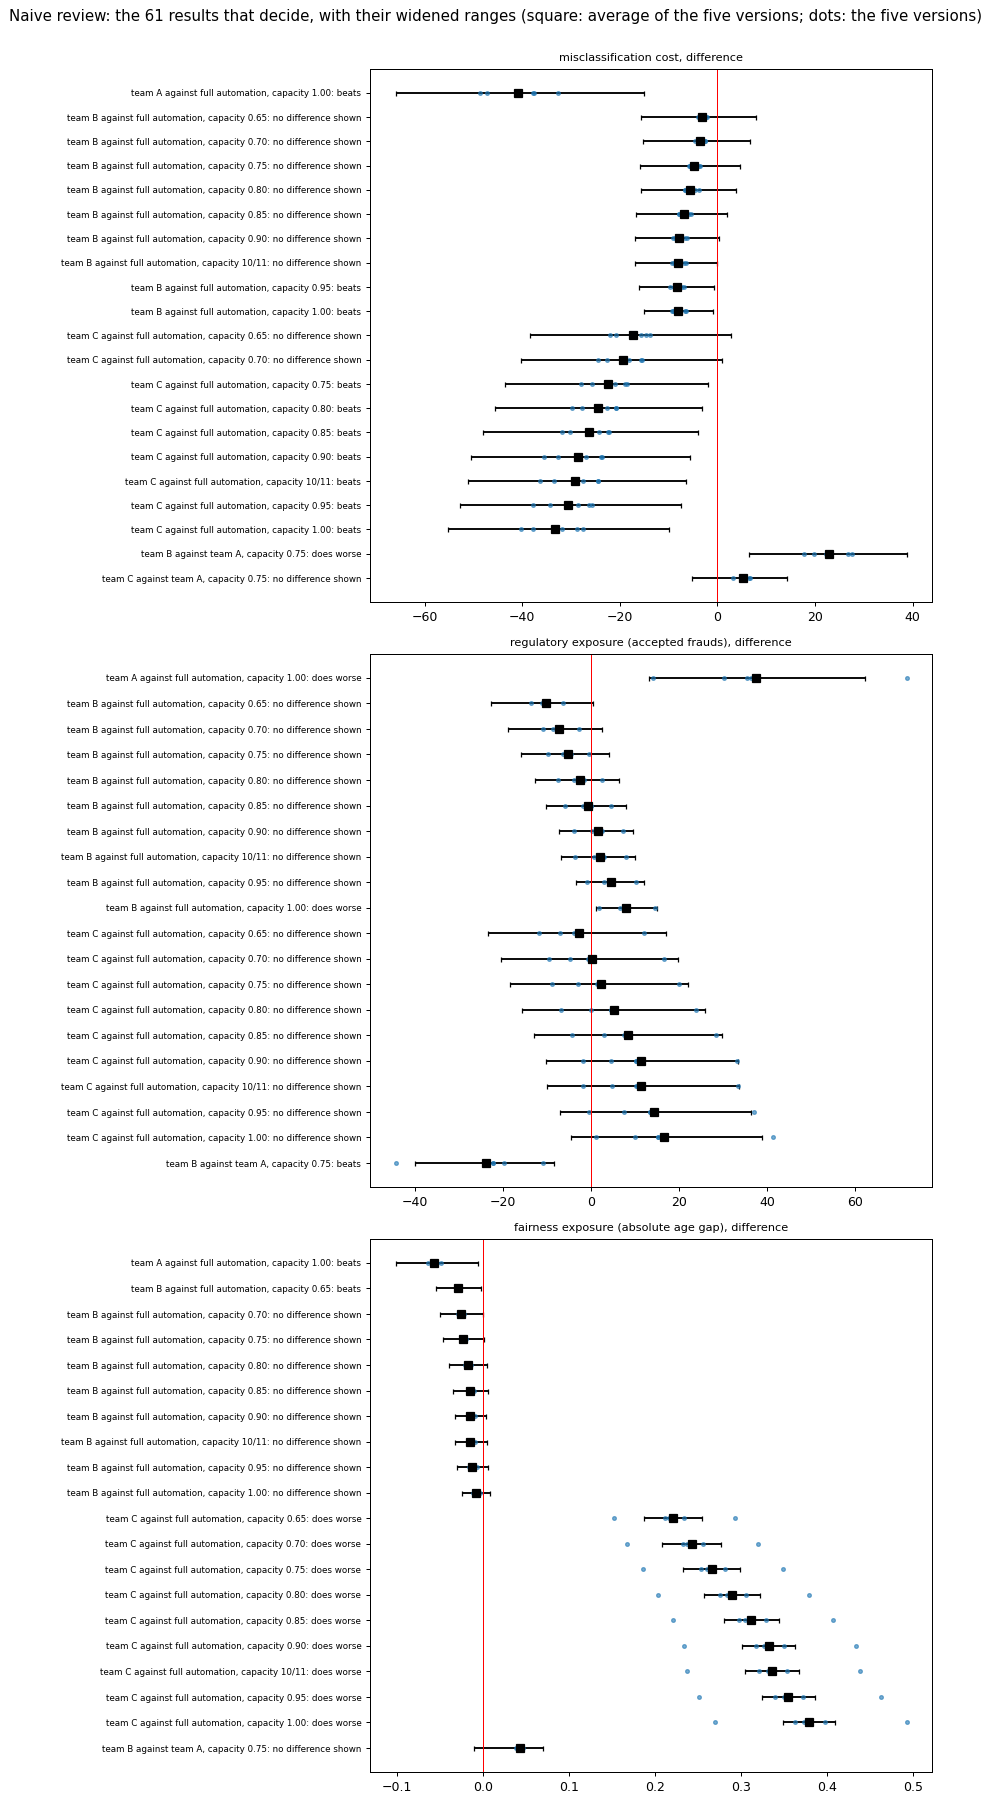

In [48]:
nb.section("T-P2-T3")

,comparison,team,capacity,measure,difference (average of the five versions),widened range (deciding),range over the five random orders,verdicts of versions 1 to 5,verdict of the average of the five,verdict,how the verdict was reached,note
0,team A at full capacity against full automation,A,1.00,"misclassification cost, difference",-72.997040,-98.0578 to -48.2701,-80.9412 to -65.0034,✅ / ✅ / ✅ / ✅ / ✅,✅,✅*,all five versions agree,—
1,team A at full capacity against full automation,A,1.00,"regulatory exposure (accepted frauds), difference",35.800000,11.8678 to 59.5200,24.6000 to 42.8000,❌ / ❌ / ❌ / 🟡 / 🟡,❌,❌*,average of the five,—
2,team A at full capacity against full automation,A,1.00,"fairness exposure (absolute age gap), difference",-0.055875,-0.1014 to -0.0055,-0.0562 to -0.0515,✅ / ✅ / ✅ / 🟡 / 🟡,✅,✅*,average of the five,—
3,team B against full automation,B,0.65,"misclassification cost, difference",-10.228280,-15.4791 to -5.0002,-12.8086 to -8.9278,✅ / ✅ / ✅ / ✅ / ✅,✅,✅*,all five versions agree,—
4,team B against full automation,B,0.65,"regulatory exposure (accepted frauds), difference",4.480000,-0.6849 to 9.4824,2 to 6.2000,🟡 / 🟡 / ❌ / 🟡 / 🟡,🟡,🟡*,average of the five,—
5,team B against full automation,B,0.65,"fairness exposure (absolute age gap), difference",-0.005846,-0.0202 to 0.0084,-0.0092 to -0.0028,🟡 / 🟡 / 🟡 / 🟡 / 🟡,🟡,🟡*,average of the five,—
6,team B against full automation,B,0.70,"misclassification cost, difference",-11.353360,-16.8148 to -5.8825,-13.8760 to -8.9538,✅ / ✅ / ✅ / ✅ / ✅,✅,✅*,all five versions agree,—
7,team B against full automation,B,0.70,"regulatory exposure (accepted frauds), difference",4.520000,-0.8400 to 9.6400,1.4000 to 7.2000,🟡 / 🟡 / ❌ / 🟡 / 🟡,🟡,🟡*,average of the five,—
8,team B against full automation,B,0.70,"fairness exposure (absolute age gap), difference",-0.006239,-0.0207 to 0.0086,-0.0097 to -0.0024,🟡 / 🟡 / 🟡 / 🟡 / 🟡,🟡,🟡*,average of the five,—
9,team B against full automation,B,0.75,"misclassification cost, difference",-12.184560,-17.8098 to -6.5147,-15.4834 to -10.2160,✅ / ✅ / ✅ / ✅ / ✅,✅,✅*,all five versions agree,—


*FPR among the alerts.*

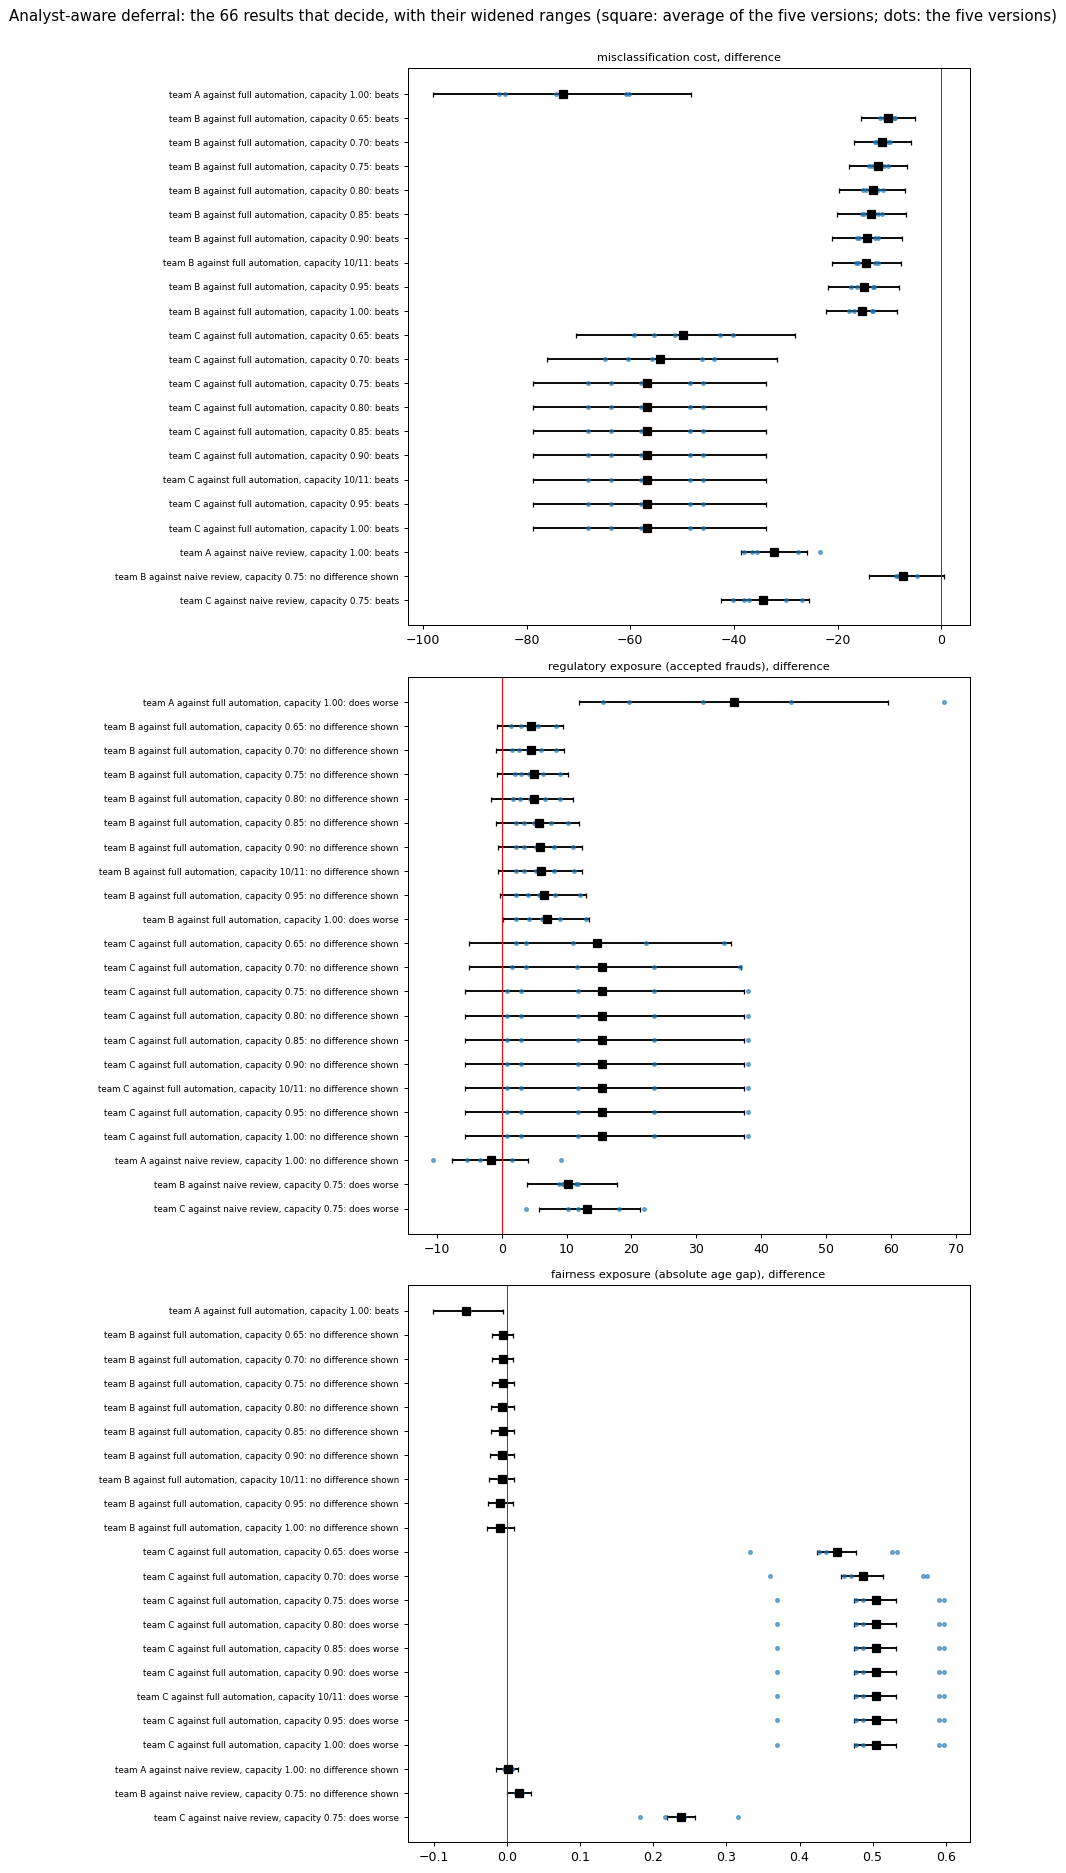

In [49]:
nb.section("T-P3-T3")

<a id="boundary-summaries-caveat"></a>
## Boundary summaries: caveat

The two table files of section 4.1 hold a column headed "summary (can be misread; see the caveat in the technical section)" (`tables/P2-T4_capacity_boundaries.csv` and `tables/P3-T4_capacity_boundaries.csv`, column `interval summary`). The rule outcomes of naive review hold summaries of the same form in their table file, which is not displayed (`tables/P2-T3c_rule_outcomes.csv`, column `boundary_summary`). This run's verdict step forms these summaries once, and the table files hold them unchanged. Where a summary reads "does worse up to capacity X; never beats", with no "between:" list, it states only the highest capacity at which the comparison does worse, and that it never beats. It does not mean "does worse at every capacity up to X". The per-capacity verdicts govern: for the rule outcomes, those of `tables/P2-T3b_realistic_range_verdicts.csv`; for section 4.1, the colour grids and the capacity columns of the two table files (average of the five versions; the rows of each version are in the table files). No verdict, rule outcome or number changes.

In this run:
- `tables/P2-T3c_rule_outcomes.csv`: one row, the rule for reviewers who agree with the model on frauds accepted ("does worse up to capacity 1.00; never beats"): team B shows no difference at 0.65 to 0.95 and does worse only at 1.
- `tables/P2-T4_capacity_boundaries.csv`: no row has this form.
- `tables/P3-T4_capacity_boundaries.csv`: 27 rows have this form, all with X = 1.00. The 8 rows against naive review (team A version 2 on frauds accepted; team C version 2 on frauds accepted; team C versions 1 to 5 and the mean on the age gap) read "does worse" at every capacity. In the 19 rows against full automation, the only other verdict is "no difference shown": at capacity 0, where analyst-aware deferral is full automation, in every row; and also, on frauds accepted, for team A version 1 at 0.05, version 2 at 0.10, version 4 at 0.05 to 0.20 and version 5 at 0.05 to 0.15; for team B version 1 at 0.05, 0.10, 0.20 and 0.55, version 2 and the mean at 0.10; and for team C version 2 and the mean at 0.05 to 0.15. The other rows of this form (frauds accepted: team A version 3 and the mean, team B version 3, team C version 3; the age gap: team C versions 1 to 5 and the mean) differ from "does worse" at capacity 0 only.

<a id="run-time-and-memory-of-this-run"></a>
## Run time and memory of this run

Each step's wall-clock time and peak memory, in bytes, computed from this run's own records while it ran. The set-up steps (environment, framework and FiFAR) run in the notebook's own process, whose memory is not measured step by step, so their memory cell shows a dash.

In [50]:
nb.run_time_table()

step,wall-clock time (s),peak memory (bytes),platform
environment: Python 3.7.9 and the pinned versions,132.8,—,linux
framework: OpenL2D at cfe5fd0 with the patches,11.7,—,linux
FiFAR: download and checks,15.9,—,linux
the applications: aggregate figures of Base.csv,33.5,"1,054,183,424",linux
regenerating the 50 reviewers,71.9,"5,828,440,064",linux
drawing the five teams,0.7,"321,253,376",linux
"policy 1, full automation",1.4,"321,253,376",linux
"policy 1, ranges (1,000 re-draws)",1.1,"321,253,376",linux
"policy 2, naive review (replay)",3.8,"688,181,248",linux
"policy 2, re-drawing the cases (50,000)",149.4,"2,400,448,512",linux


<a id="this-runs-outputs-in-one-archive"></a>
## This run's outputs in one archive

The last cell collects a description of this run's outputs in one archive, `savehitl_returned_outputs.zip`, so that they can be kept after the session ends; on Colab it also offers the archive for download. Among other records of the run, it holds the table files, the per-column summaries of the run's case-level files (for columns of numbers: count, sum, sum of absolute values, minimum and maximum; for other columns: count, number of distinct values and a checksum of the values), the checksums of the router's 250 refitted models, and the run's time and memory records. It holds no case row of FiFAR. Nothing else in the notebook depends on this cell.

In [51]:
nb.hand_back()

savehitl_returned_outputs.zip: 6,337,002 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>